# 4 Real-Time Water Quality Monitoring with Wavelet Denoising


## 4.4 Water Quality Dataset
### 4.4.3 Data Statistics amd Visualization

=== Descriptive Statistics (Transposed) ===
       count       mean       std        min        25%        50%        75%  \
pH   17478.0   8.451081  0.257026   7.632042   8.242667   8.454550   8.650392   
DO   17478.0   7.332330  3.475426   1.470106   4.385123   7.449556  10.158551   
WT   17478.0  25.527729  3.501192  16.959654  23.322527  26.364579  27.567807   
NH   17478.0   0.760502  0.811604   0.005957   0.037025   0.613246   1.216601   
EC   17478.0   0.915428  0.015817   0.872412   0.905852   0.917028   0.927334   
TUR  17478.0  22.297660  9.234430   1.323378  15.725516  20.415314  27.631571   

           max  
pH    9.092802  
DO   14.774368  
WT   32.545376  
NH    2.980824  
EC    0.948271  
TUR  48.473964  


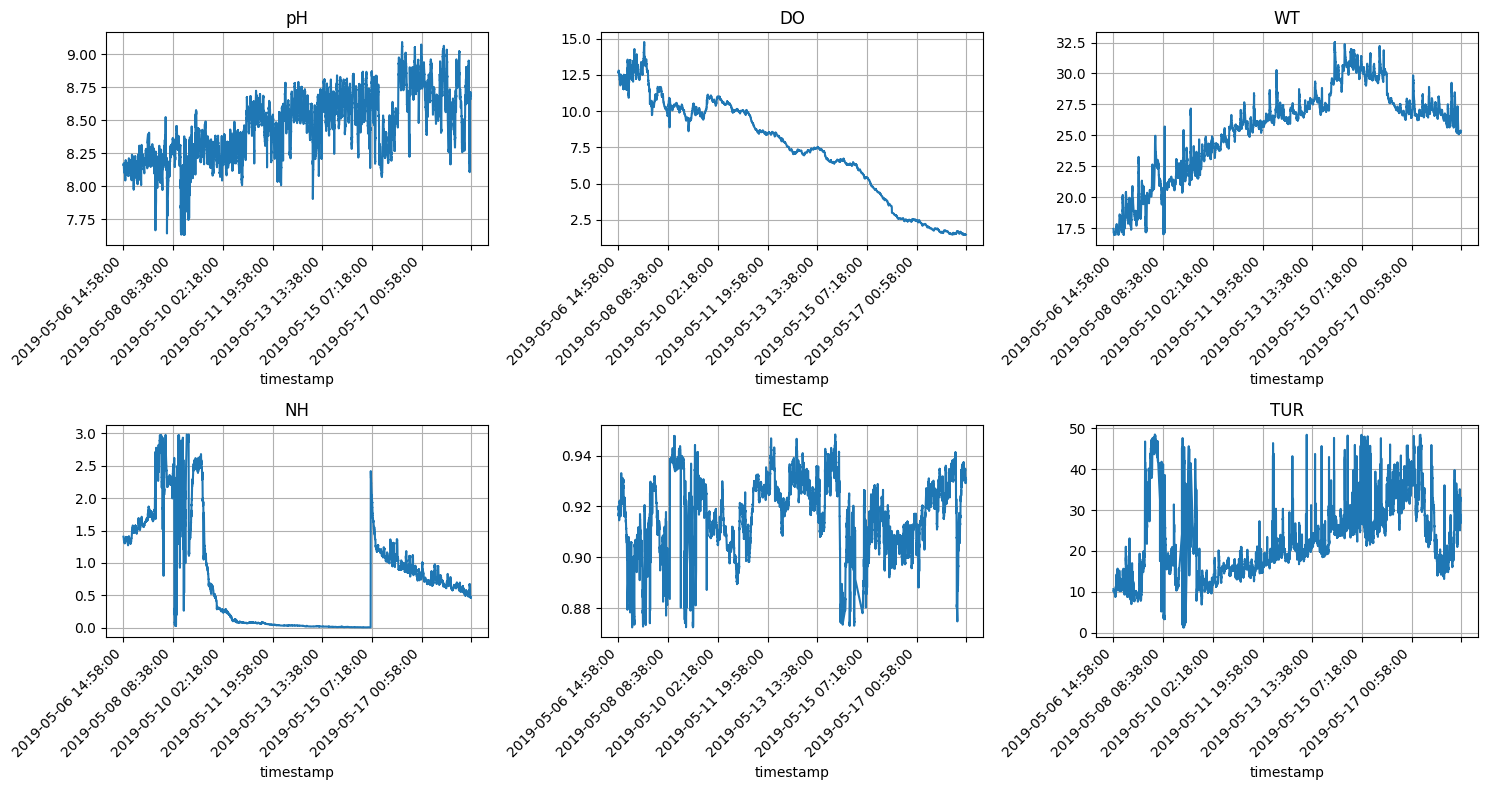

✅ Plot saved to: ./output\26.1_data_visualization_line.png


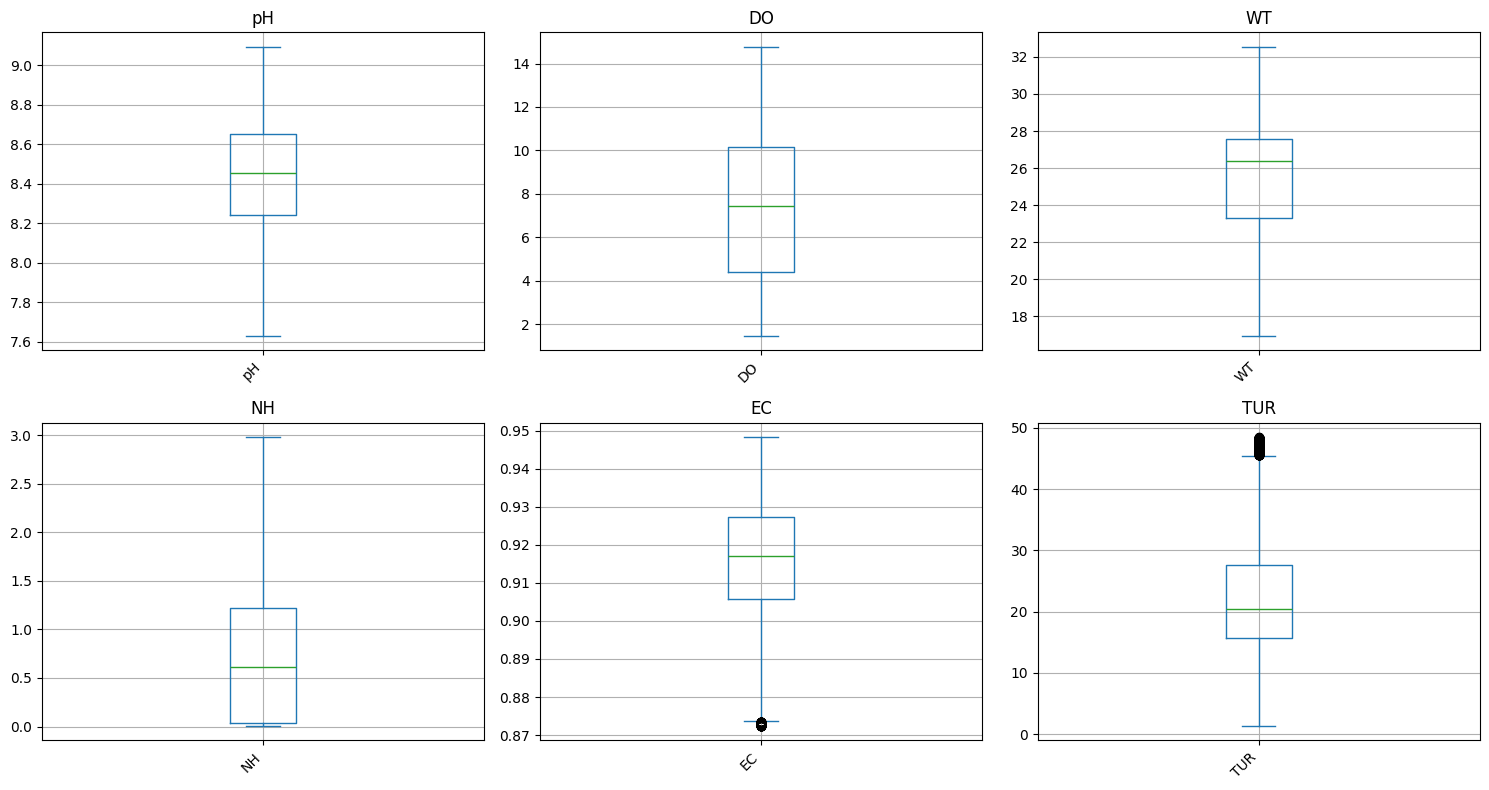

✅ Plot saved to: ./output\26.2_data_visualization_box.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import os

def describe_data(df):
    """
    Print descriptive statistics of numeric columns (transposed).
    """
    desc = df.describe().T
    print("=== Descriptive Statistics (Transposed) ===")
    print(desc)
    return desc


def plot_grid(df, kind="hist", output_dir="./output", base_filename="data_visualization"):
    """
    Plot multiple numeric columns in a dynamic grid and save figure.

    Parameters:
        df         : DataFrame
        kind       : str, type of plot ('hist', 'line', 'box', 'bar')
        output_dir : str, directory to save plots
        base_filename : str, base name for saved figure
    """
    # Ensure output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # Select numeric columns
    numeric_cols = df.select_dtypes(include='number').columns
    if len(numeric_cols) == 0:
        raise ValueError("No numeric columns found to plot.")

    n = len(numeric_cols)
    cols = math.ceil(math.sqrt(n))
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows), sharex=False)
    axes = axes.flatten() if n > 1 else [axes]

    for i, col in enumerate(numeric_cols):
        ax = axes[i]
        if kind == "hist":
            df[col].plot(kind=kind, bins=20, alpha=0.7, ax=ax)
        else:
            df[col].plot(kind=kind, ax=ax)
        ax.set_title(col)
        ax.grid(True)

    # Remove extra axes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    filename = f"{base_filename}_{kind}.png"
    filepath = os.path.join(output_dir, filename)
    plt.savefig(filepath)
    plt.show()
    print(f"✅ Plot saved to: {filepath}")


def data_visualization(df, kind="hist", output_dir="./output", number_=None, base_filename="data_visualization"):
    """
    Plot multiple numeric columns in a dynamic grid and save figure.

    Parameters:
        df         : DataFrame
        kind       : str, type of plot ('hist', 'line', 'box', 'bar')
        output_dir : str, directory to save plots
        base_filename : str, base name for saved figure
    """
    import matplotlib.dates as mdates

    # Ensure output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # Select numeric columns
    numeric_cols = df.select_dtypes(include='number').columns
    if len(numeric_cols) == 0:
        raise ValueError("No numeric columns found to plot.")

    n = len(numeric_cols)
    cols = math.ceil(math.sqrt(n))
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows), sharex=False)
    axes = axes.flatten() if n > 1 else [axes]

    for i, col in enumerate(numeric_cols):
        ax = axes[i]
        if kind == "hist":
            df[col].plot(kind=kind, bins=20, alpha=0.7, ax=ax)
        else:
            df[col].plot(kind=kind, ax=ax)

        ax.set_title(col)
        ax.grid(True)

        # --- Fix crowded x-axis labels ---
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

        # If index is datetime, use auto-formatting
        if pd.api.types.is_datetime64_any_dtype(df.index):
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

    # Remove extra axes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    filename = f"{number_}{base_filename}_{kind}.png"
    filepath = os.path.join(output_dir, filename)
    plt.savefig(filepath, bbox_inches="tight")
    plt.show()
    print(f"✅ Plot saved to: {filepath}")



# Example usage
if __name__ == "__main__":
    df = pd.read_csv("./data/water_quality_data.csv", index_col=0)

    # Describe data
    describe_data(df)

    # Plot and save multiple kinds
    data_visualization(df, kind="line", number_="26.1_")
    data_visualization(df, kind="box", number_="26.2_")



## 4.4 Water Quality Dataset

### 4.4.3 Data Quality Assessment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import streamlit as st

def assess_data_quality(df):
    """Comprehensive data quality assessment"""
    print("=== DATA QUALITY ASSESSMENT ===")
    
    # Missing data analysis
    missing_data = df.isnull().sum()
    missing_percent = (missing_data / len(df)) * 100
    
    print(f"\nDataset shape: {df.shape}")
    print(f"Date range: {df.index.min()} to {df.index.max()}")
    print(f"Sampling frequency: {df.index.to_series().diff().mode().iloc[0]}")
    
    print("\nMissing Data Analysis:")
    for param in df.columns:
        print(f"  {param}: {missing_data[param]} ({missing_percent[param]:.2f}%)")
    
    # Outlier detection using IQR method
    print("\nOutlier Analysis (IQR method):")
    for param in df.columns:
        Q1 = df[param].quantile(0.25)
        Q3 = df[param].quantile(0.75)
        IQR = Q3 - Q1
        outliers = ((df[param] < (Q1 - 1.5 * IQR)) | 
                   (df[param] > (Q3 + 1.5 * IQR))).sum()
        print(f"  {param}: {outliers} outliers ({(outliers/len(df))*100:.2f}%)")
    
    # Noise level estimation
    print("\nNoise Level Estimation (std of differences):")
    for param in df.columns:
        noise_level = df[param].diff().std()
        signal_level = df[param].std()
        snr = signal_level / noise_level if noise_level > 0 else np.inf
        print(f"  {param}: SNR ≈ {snr:.2f}")
    
    return missing_data, missing_percent

# Example usage
if __name__ == "__main__":
    # read sample data
    df = pd.read_csv("./data/water_quality_data.csv", parse_dates=["timestamp"])

    # Set timestamp as index and resample to 1-minute intervals, interpolating missing values
    df = df.set_index("timestamp").resample("1min").mean().interpolate()
    missing_data, missing_percent = assess_data_quality(df)

=== DATA QUALITY ASSESSMENT ===

Dataset shape: (17478, 6)
Date range: 2019-05-06 14:58:00 to 2019-05-18 18:15:00
Sampling frequency: 0 days 00:01:00

Missing Data Analysis:
  pH: 0 (0.00%)
  DO: 0 (0.00%)
  WT: 0 (0.00%)
  NH: 0 (0.00%)
  EC: 0 (0.00%)
  TUR: 0 (0.00%)

Outlier Analysis (IQR method):
  pH: 0 outliers (0.00%)
  DO: 0 outliers (0.00%)
  WT: 0 outliers (0.00%)
  NH: 0 outliers (0.00%)
  EC: 62 outliers (0.35%)
  TUR: 264 outliers (1.51%)

Noise Level Estimation (std of differences):
  pH: SNR ≈ 11.18
  DO: SNR ≈ 113.37
  WT: SNR ≈ 35.41
  NH: SNR ≈ 20.58
  EC: SNR ≈ 8.64
  TUR: SNR ≈ 5.36


### 4.5.1 Comprehensive Data Cleaning

Handling missing values...
Resampling to consistent intervals...
Removing outliers...
Preprocessing complete. Final shape: (17478, 6)
                           pH         DO         WT        NH        EC  \
timestamp                                                                 
2019-05-06 14:58:00  8.162049  12.661514  17.446314  1.404537  0.918846   
2019-05-06 14:59:00  8.167172  12.623893  17.441256  1.399529  0.919983   
2019-05-06 15:00:00  8.167777  12.627376  17.436554  1.398306  0.920150   
2019-05-06 15:01:00  8.167861  12.616008  17.440655  1.398544  0.920082   
2019-05-06 15:02:00  8.167942  12.625122  17.438456  1.398110  0.920104   

                           TUR  
timestamp                       
2019-05-06 14:58:00  10.688290  
2019-05-06 14:59:00  10.481971  
2019-05-06 15:00:00  10.433970  
2019-05-06 15:01:00  10.413547  
2019-05-06 15:02:00  10.415664  


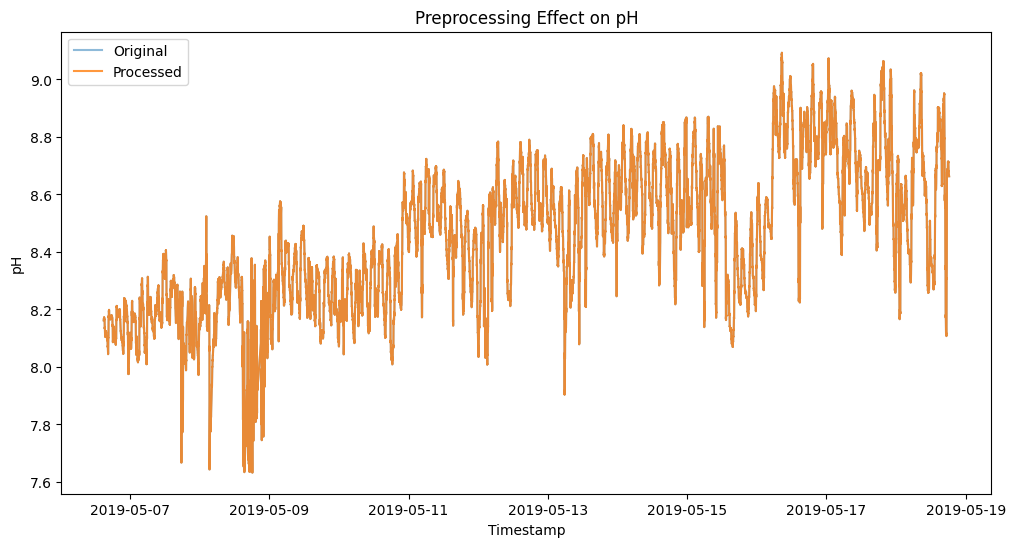

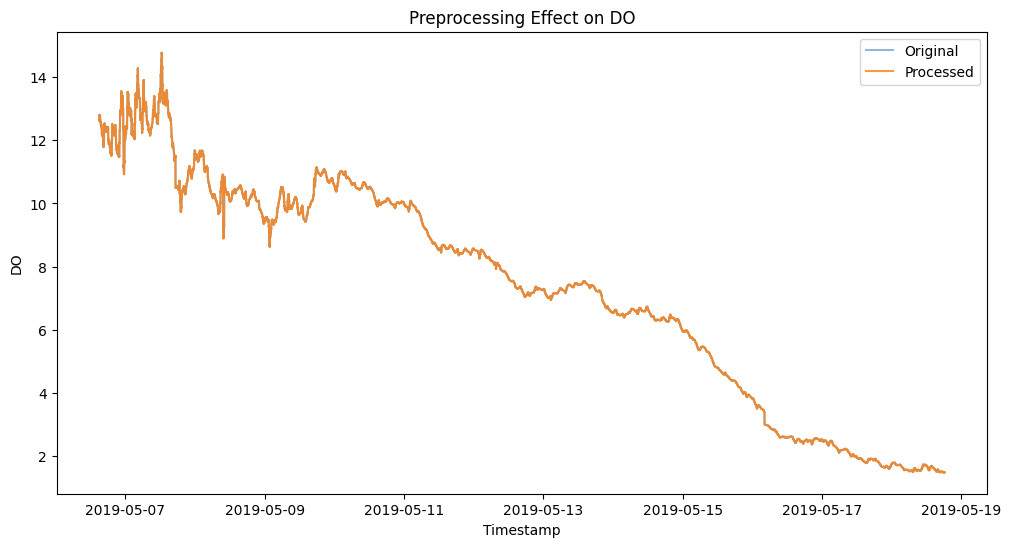

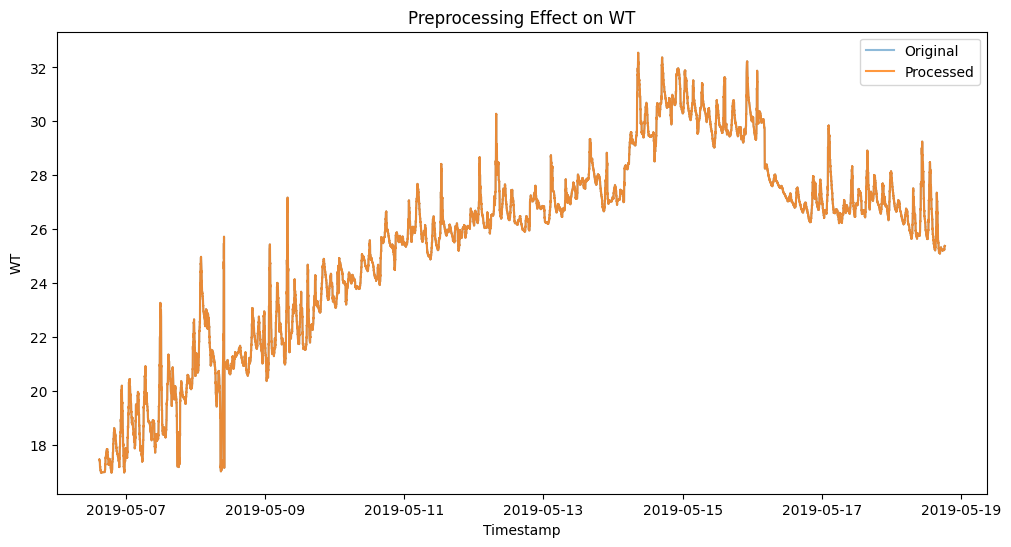

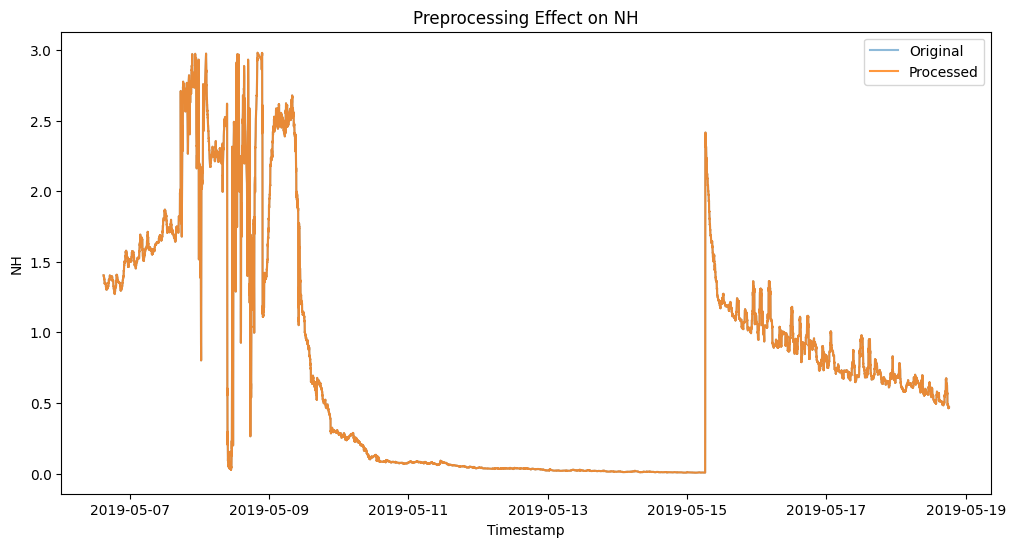

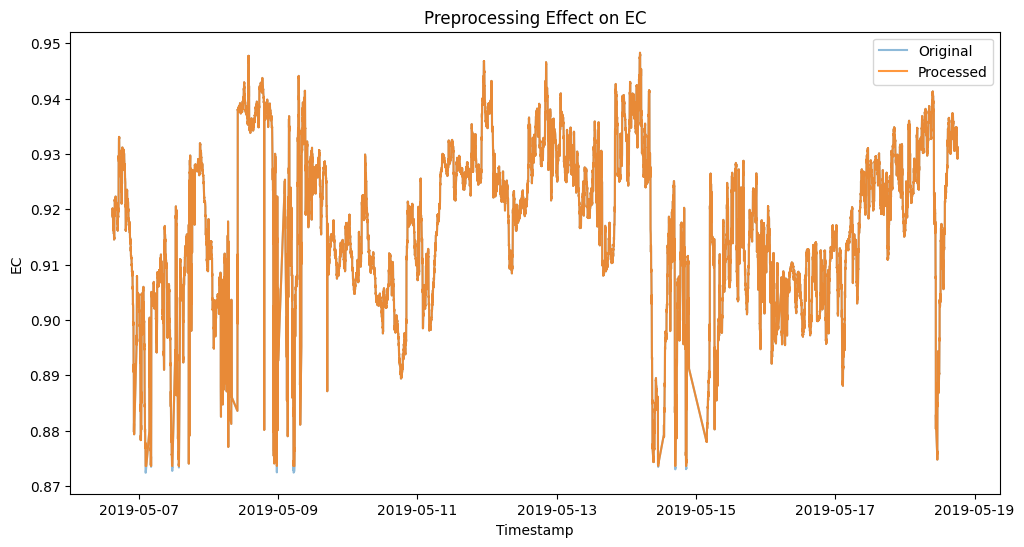

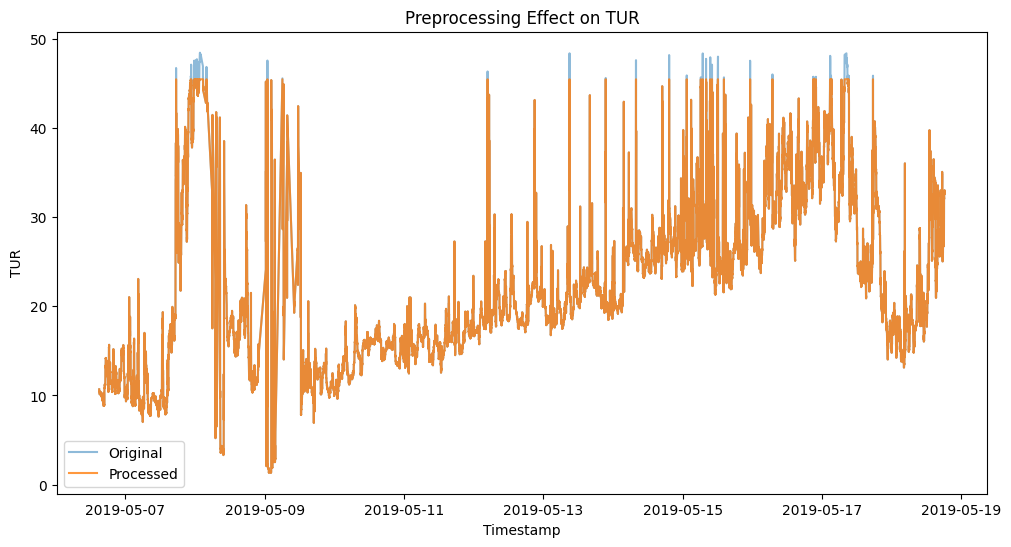

In [11]:
import pandas as pd
import numpy as np
from scipy import interpolate
from sklearn.preprocessing import RobustScaler

class WaterQualityPreprocessor:
    def __init__(self):
        self.scaler = RobustScaler()
        self.interpolation_methods = {
            'pH': 'linear',
            'DO': 'cubic',
            'EC': 'linear',
            'NH': 'linear',
            'TUR': 'linear',
            'WT': 'cubic'
        }
        
    def load_and_clean_data(self, filepath):
        """Load and perform initial cleaning"""
        df = pd.read_csv(filepath, parse_dates=['timestamp'])
        df = df.set_index('timestamp')
        
        # Remove duplicate timestamps
        df = df[~df.index.duplicated(keep='first')]
        
        # Sort by timestamp
        df = df.sort_index()
        
        return df
    
    def handle_missing_values(self, df):
        """Advanced missing value handling"""
        df_clean = df.copy()
        
        for column in df.columns:
            missing_mask = df_clean[column].isnull()
            
            if missing_mask.sum() > 0:
                # Use appropriate interpolation method for each parameter
                method = self.interpolation_methods.get(column, 'linear')
                
                if method == 'cubic' and missing_mask.sum() < len(df) * 0.1:
                    # Cubic interpolation for smooth parameters (low missing rate)
                    df_clean[column] = df_clean[column].interpolate(
                        method='cubic', limit_direction='both'
                    )
                else:
                    # Linear interpolation as fallback
                    df_clean[column] = df_clean[column].interpolate(
                        method='linear', limit_direction='both'
                    )
                
                # Forward/backward fill for remaining NaN values
                df_clean[column] = df_clean[column].bfill().ffill()
        
        return df_clean
    
    def resample_data(self, df, frequency='1min'):
        """Resample to consistent time intervals"""
        return df.resample(frequency).mean()
    
    def remove_outliers(self, df, method='iqr', threshold=1.5):
        """Remove statistical outliers"""
        df_clean = df.copy()
        
        for column in df.columns:
            if method == 'iqr':
                Q1 = df[column].quantile(0.25)
                Q3 = df[column].quantile(0.75)
                IQR = Q3 - Q1
                
                lower_bound = Q1 - threshold * IQR
                upper_bound = Q3 + threshold * IQR
                
                # Replace outliers with boundary values (winsorizing)
                df_clean[column] = df_clean[column].clip(lower_bound, upper_bound)
            
            elif method == 'zscore':
                z_scores = np.abs((df[column] - df[column].mean()) / df[column].std())
                df_clean[column] = df_clean[column].mask(z_scores > threshold, 
                                                        df[column].median())
        
        return df_clean
    
    def preprocess(self, df):
        """Complete preprocessing pipeline (expects DataFrame)"""
        print("Handling missing values...")
        df = self.handle_missing_values(df)
        
        print("Resampling to consistent intervals...")
        df = self.resample_data(df)
        
        print("Removing outliers...")
        df = self.remove_outliers(df)
        
        print(f"Preprocessing complete. Final shape: {df.shape}")
        return df

# Example usage
if __name__ == "__main__":
    preprocessor = WaterQualityPreprocessor()
    
    # Load dataset
    df = preprocessor.load_and_clean_data("./data/water_quality_data.csv")
    
    # Run preprocessing pipeline
    processed_df = preprocessor.preprocess(df)
    
    print(processed_df.head())

    import matplotlib.pyplot as plt
    
    # Loop through all numeric columns and plot original vs processed
    for param in df.select_dtypes(include=[np.number]).columns:
        plt.figure(figsize=(12, 6))
        plt.plot(df.index, df[param], label='Original', alpha=0.5)
        plt.plot(processed_df.index, processed_df[param], label='Processed', alpha=0.8)
        plt.title(f'Preprocessing Effect on {param}')
        plt.xlabel('Timestamp')
        plt.ylabel(param)
        plt.legend()
        plt.show()

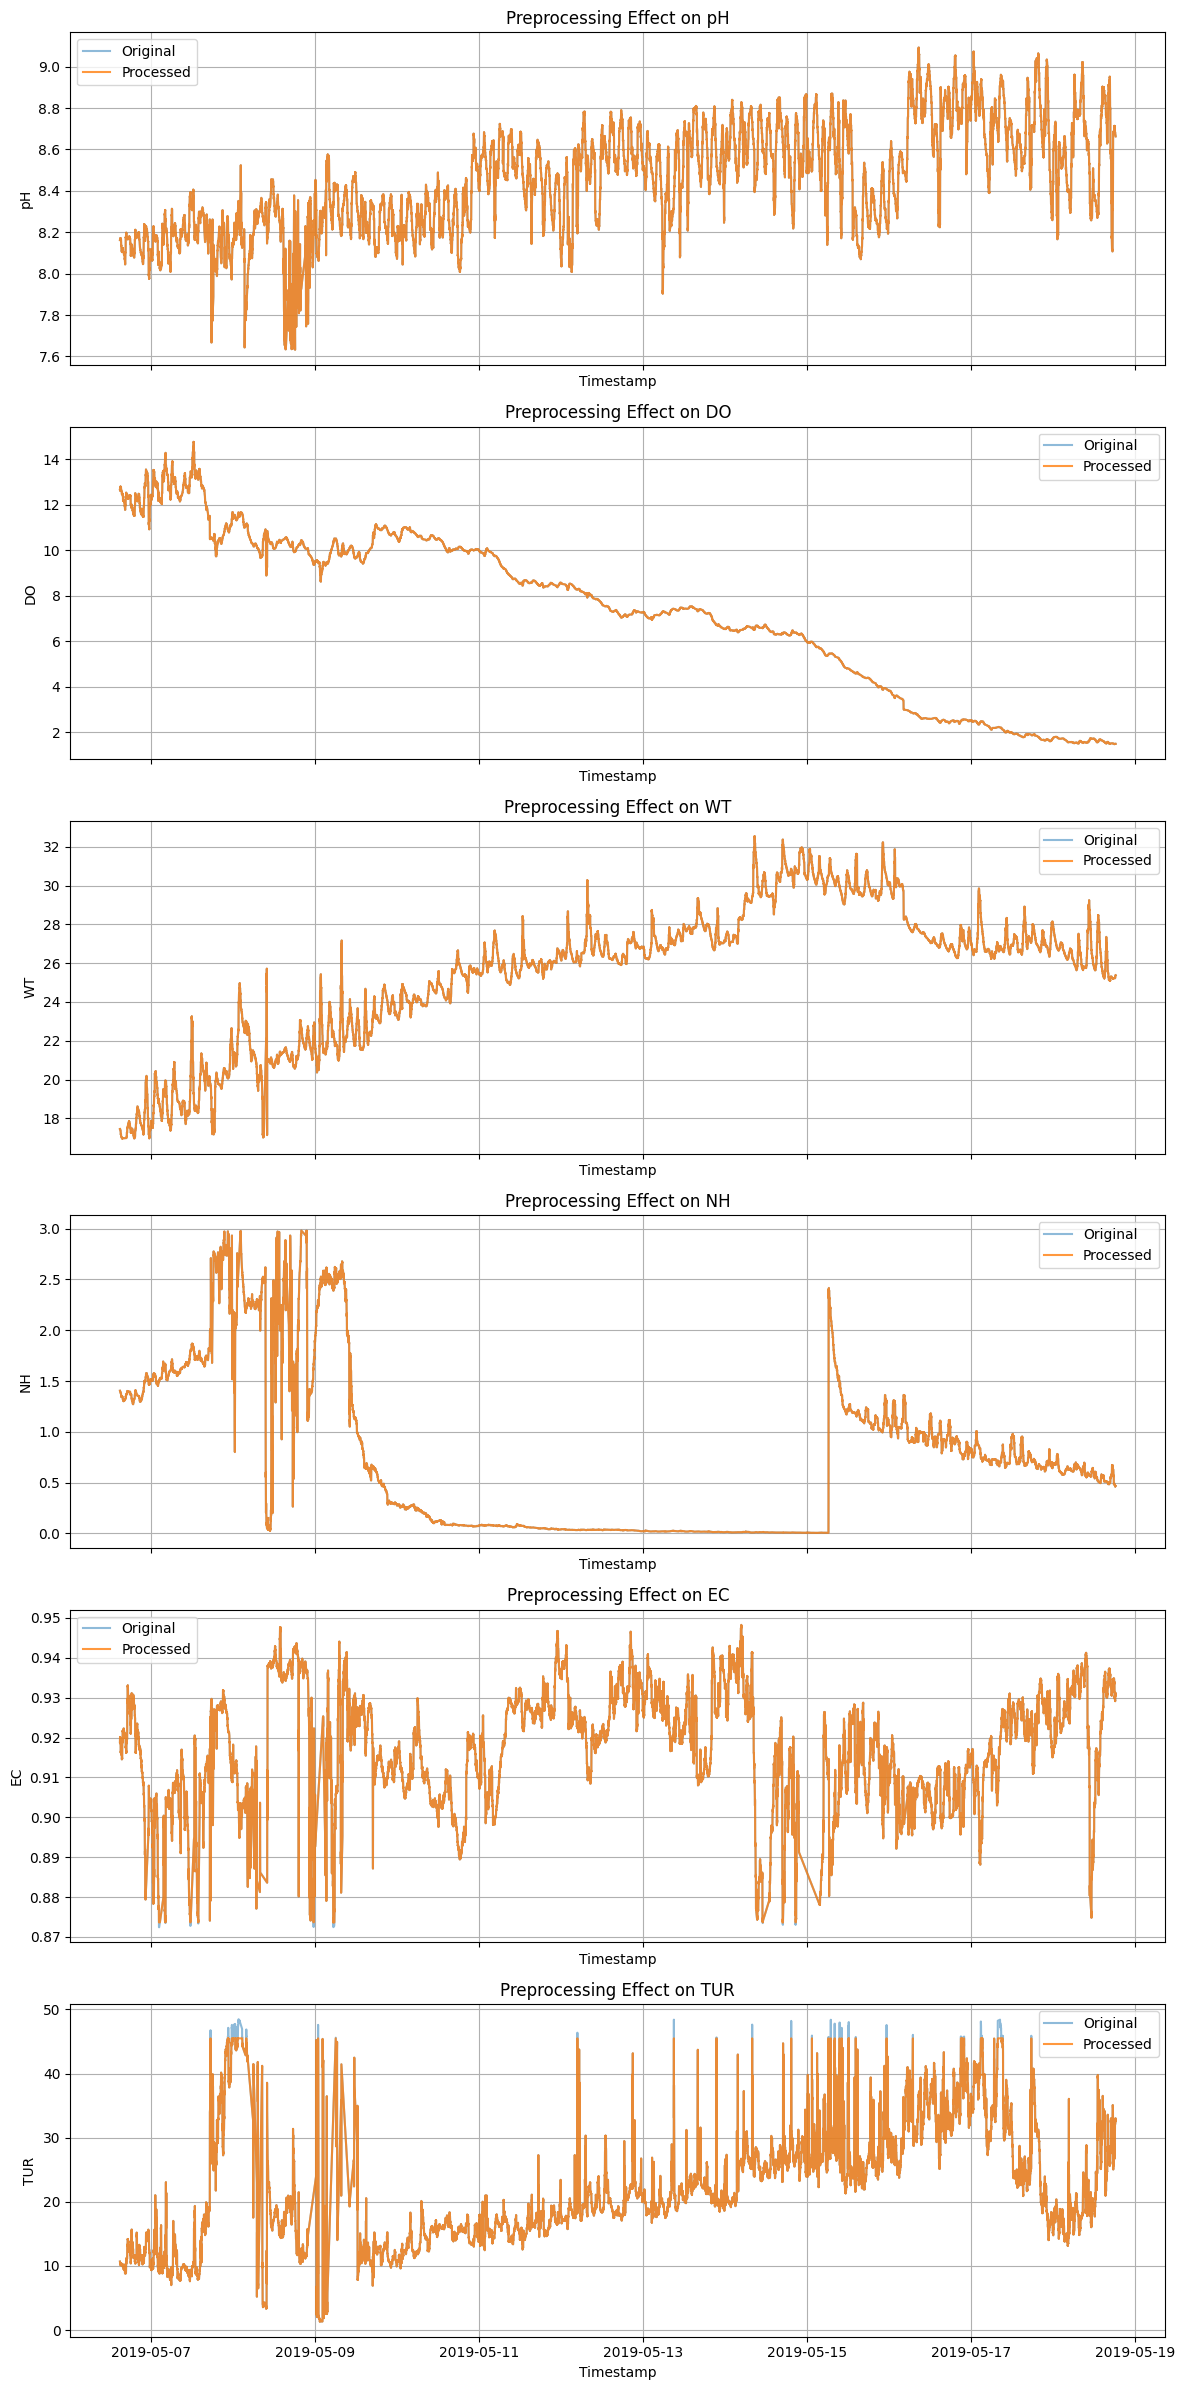

In [12]:
# Subplot all numeric parameters: original vs processed
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include=[np.number]).columns
n_cols = len(numeric_cols)
fig, axes = plt.subplots(n_cols, 1, figsize=(12, 4 * n_cols), sharex=True)

if n_cols == 1:
    axes = [axes]

for idx, param in enumerate(numeric_cols):
    ax = axes[idx]
    ax.plot(df.index, df[param], label='Original', alpha=0.5)
    ax.plot(processed_df.index, processed_df[param], label='Processed', alpha=0.8)
    ax.set_title(f'Preprocessing Effect on {param}')
    ax.set_xlabel('Timestamp')
    ax.set_ylabel(param)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 4.5.2 Advanced Interpolation Strategies

In [8]:
def parameter_specific_interpolation(df):
    """Apply parameter-specific interpolation strategies"""
    df_interpolated = df.copy()
    
    # Temperature: Smooth diurnal variation - cubic spline
    if 'WT' in df.columns:
        df_interpolated['WT'] = df['WT'].interpolate(method='cubic')
    
    # pH: Chemical equilibrium - linear interpolation
    if 'pH' in df.columns:
        df_interpolated['pH'] = df['pH'].interpolate(method='linear')
    
    # DO: Biological processes - time-aware interpolation
    if 'DO' in df.columns:
        df_interpolated['DO'] = df['DO'].interpolate(method='time')
    
    # Conductivity: Conservative mixing - linear
    if 'EC' in df.columns:
        df_interpolated['EC'] = df['EC'].interpolate(method='linear')

    # Ammonia: Episodic spikes - forward fill then backward fill
    if 'NH' in df.columns:
        df_interpolated['NH'] = df['NH'].ffill().bfill()
    
    # Turbidity: Event-driven - linear interpolation
    if 'TUR' in df.columns:
        df_interpolated['TUR'] = df['TUR'].interpolate(method='linear')
    
    return df_interpolated

# example usage
if __name__ == "__main__":
    df = pd.read_csv("./data/water_quality_data.csv", parse_dates=["timestamp"])
    df = df.set_index("timestamp").resample("1min").mean()
    df_interpolated = parameter_specific_interpolation(df)
    print(df_interpolated.head())


                           pH         DO         WT        NH        EC  \
timestamp                                                                 
2019-05-06 14:58:00  8.162049  12.661514  17.446314  1.404537  0.918846   
2019-05-06 14:59:00  8.167172  12.623893  17.441256  1.399529  0.919983   
2019-05-06 15:00:00  8.167777  12.627376  17.436554  1.398306  0.920150   
2019-05-06 15:01:00  8.167861  12.616008  17.440655  1.398544  0.920082   
2019-05-06 15:02:00  8.167942  12.625122  17.438456  1.398110  0.920104   

                           TUR  
timestamp                       
2019-05-06 14:58:00  10.688290  
2019-05-06 14:59:00  10.481971  
2019-05-06 15:00:00  10.433970  
2019-05-06 15:01:00  10.413547  
2019-05-06 15:02:00  10.415664  


## 4.6 Advanced Wavelet Denoising Implementation

### 4.6.1 Multi-Scale Denoising Framework

In [5]:
import pywt
import numpy as np
import pandas as pd
import warnings
from scipy.stats import median_abs_deviation


class AdvancedWaveletDenoiser:
    def __init__(self):
        self.wavelet_families = {
            'smooth': ['db4', 'db8', 'coif4'],
            'oscillatory': ['db2', 'haar', 'bior2.2'],
            'irregular': ['db6', 'sym4', 'dmey']
        }
        
    def estimate_noise_level(self, signal):
        """Estimate noise level using median absolute deviation"""
        coeffs = pywt.wavedec(signal, 'db1', level=1)
        sigma = median_abs_deviation(coeffs[-1]) / 0.6745
        return sigma
    
    def adaptive_threshold_selection(self, coeffs, method='bayes', noise_sigma=None):
        """Adaptive threshold selection"""
        n = len(coeffs)

        if method == 'bayes':
            # Bayes threshold uses estimated noise sigma
            if noise_sigma is None:
                noise_sigma = median_abs_deviation(coeffs) / 0.6745
            threshold = noise_sigma * np.sqrt(2 * np.log(n))
            
        elif method == 'sure':
            # SURE threshold (Stein's Unbiased Risk Estimate)
            coeffs_abs = np.abs(coeffs)
            coeffs_sorted = np.sort(coeffs_abs)

            risks = np.zeros(n)
            for i, t in enumerate(coeffs_sorted):
                risks[i] = (
                    n - 2 * (i + 1) +
                    np.sum(coeffs_abs[coeffs_abs <= t] ** 2) +
                    t ** 2 * (n - i - 1)
                )
            threshold = coeffs_sorted[np.argmin(risks)]
            
        else:
            raise ValueError(f"Unknown threshold selection method: {method}")
        
        return threshold
    
    def multi_level_denoising(self, signal, wavelet='db4', levels=6, 
                             threshold_mode='soft', selection_method='bayes'):
        """Advanced multi-level wavelet denoising"""
        
        # Perform multi-level decomposition
        coeffs = pywt.wavedec(signal, wavelet, level=levels)
        
        # Estimate noise level from finest detail coefficients
        noise_sigma = self.estimate_noise_level(signal)
        
        # Process each level of detail coefficients
        coeffs_thresh = [coeffs[0]]  # Keep approximation coefficients
        
        for detail_coeffs in coeffs[1:]:
            # Adaptive threshold for each level
            level_threshold = self.adaptive_threshold_selection(
                detail_coeffs, method=selection_method, noise_sigma=noise_sigma
            )
            
            # Apply thresholding safely
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)

                if threshold_mode == 'soft':
                    thresh = pywt.threshold(detail_coeffs, level_threshold, mode='soft')
                elif threshold_mode == 'hard':
                    thresh = pywt.threshold(detail_coeffs, level_threshold, mode='hard')
                else:  # adaptive mix
                    soft_part = pywt.threshold(detail_coeffs, level_threshold, mode='soft')
                    hard_part = pywt.threshold(detail_coeffs, level_threshold, mode='hard')
                    thresh = np.where(
                        np.abs(detail_coeffs) > 2 * level_threshold,
                        soft_part,
                        hard_part
                    )

            # Replace NaNs with safe values
            thresh = np.nan_to_num(thresh, nan=0.0)
            coeffs_thresh.append(thresh)
        
        # Reconstruct the signal
        denoised_signal = pywt.waverec(coeffs_thresh, wavelet)
        
        # Ensure same length as original signal
        return denoised_signal[:len(signal)]
    
    def parameter_optimized_denoising(self, signal, parameter_name):
        """Parameter-specific denoising optimization"""
        
        parameter_configs = {
            'pH': {'wavelet': 'db6', 'levels': 4, 'mode': 'soft'},
            'DO': {'wavelet': 'db8', 'levels': 5, 'mode': 'soft'},
            'COD': {'wavelet': 'db4', 'levels': 6, 'mode': 'adaptive'},
            'EC': {'wavelet': 'coif4', 'levels': 4, 'mode': 'soft'},
            'NH': {'wavelet': 'db6', 'levels': 5, 'mode': 'hard'},
            'TUR': {'wavelet': 'db4', 'levels': 4, 'mode': 'adaptive'},
            'WT': {'wavelet': 'db8', 'levels': 3, 'mode': 'soft'}
        }
        
        config = parameter_configs.get(
            parameter_name, {'wavelet': 'db4', 'levels': 4, 'mode': 'soft'}
        )
        
        return self.multi_level_denoising(
            signal, 
            wavelet=config['wavelet'],
            levels=config['levels'],
            threshold_mode=config['mode']
        )
    
    def denoise_dataframe(self, df):
        df_denoised = df.copy()
        noise_stats = {}
        
        for column in df.select_dtypes(include=[np.number]).columns:
            print(f"Denoising {column}...")
            denoised_signal = self.parameter_optimized_denoising(df[column].values, column)
            df_denoised[column] = denoised_signal
            
            # Estimate noise reduction ratio
            original_var = np.var(np.diff(df[column].values))
            denoised_var = np.var(np.diff(denoised_signal))
            noise_stats[column] = denoised_var / original_var
            
        return df_denoised, noise_stats
    

# Example usage
if __name__ == "__main__": 
    df = pd.read_csv("./data/water_quality_data.csv", parse_dates=["timestamp"])
    df = df.set_index("timestamp").resample("1min").mean().interpolate()
    
    denoiser = AdvancedWaveletDenoiser()
    df_denoised, noise_stats = denoiser.denoise_dataframe(df)

    print(df_denoised.head())
    print(noise_stats)   # optional: inspect noise reduction ratios


Denoising pH...
Denoising DO...
Denoising WT...
Denoising NH...
Denoising EC...
Denoising TUR...
                           pH         DO         WT        NH        EC  \
timestamp                                                                 
2019-05-06 14:58:00  8.169323  12.655841  17.453768  1.404840  0.919685   
2019-05-06 14:59:00  8.169389  12.630920  17.452426  1.402556  0.919753   
2019-05-06 15:00:00  8.169436  12.636312  17.449977  1.398817  0.919808   
2019-05-06 15:01:00  8.169458  12.622962  17.445259  1.397598  0.919754   
2019-05-06 15:02:00  8.169455  12.626169  17.437150  1.397490  0.919635   

                           TUR  
timestamp                       
2019-05-06 14:58:00  10.421875  
2019-05-06 14:59:00  10.403281  
2019-05-06 15:00:00  10.381043  
2019-05-06 15:01:00  10.354866  
2019-05-06 15:02:00  10.327328  
{'pH': 0.6325774392519973, 'DO': 0.8758279933645735, 'WT': 0.7766128135821669, 'NH': 0.9995086922273944, 'EC': 0.6943688277037355, 'TUR': 0.836268

### 4.6.2 Quality Assessment Metrics

In [6]:
def calculate_denoising_metrics(original, denoised):
    """Calculate comprehensive denoising performance metrics"""
    
    # Signal-to-Noise Ratio improvement
    original_noise = np.var(np.diff(original))
    denoised_noise = np.var(np.diff(denoised))
    snr_improvement = 10 * np.log10(original_noise / denoised_noise)
    
    # Mean Squared Error
    mse = np.mean((original - denoised)**2)
    
    # Pearson correlation (signal preservation)
    correlation = np.corrcoef(original, denoised)[0, 1]
    
    # Peak preservation (important for anomaly detection)
    original_peaks = np.abs(original - np.median(original)) > 2 * np.std(original)
    denoised_peaks = np.abs(denoised - np.median(denoised)) > 2 * np.std(denoised)
    peak_preservation = np.sum(original_peaks & denoised_peaks) / np.sum(original_peaks)
    
    return {
        'snr_improvement_db': snr_improvement,
        'mse': mse,
        'correlation': correlation,
        'peak_preservation': peak_preservation,
        'noise_reduction_ratio': denoised_noise / original_noise
    }

# Example usage of metrics calculation
if __name__ == "__main__":
    df = pd.read_csv("./data/water_quality_data.csv", parse_dates=["timestamp"])
    df = df.set_index("timestamp").resample("1min").mean().interpolate()
    
    denoiser = AdvancedWaveletDenoiser()
    df_denoised, noise_stats = denoiser.denoise_dataframe(df)
    
    print("\nDenoising performance metrics per parameter:")
    for param in df.select_dtypes(include=[np.number]).columns:
        original = df[param].values
        denoised = df_denoised[param].values
        metrics = calculate_denoising_metrics(original, denoised)
        print(f"{param}: {metrics}")

Denoising pH...
Denoising DO...
Denoising WT...
Denoising NH...
Denoising EC...
Denoising TUR...

Denoising performance metrics per parameter:
pH: {'snr_improvement_db': 1.988863011700353, 'mse': 5.8529567498836194e-05, 'correlation': 0.9995577349301085, 'peak_preservation': 0.974903474903475, 'noise_reduction_ratio': 0.6325774392519973}
DO: {'snr_improvement_db': 0.575811779273207, 'mse': 1.8655676887025157e-05, 'correlation': 0.9999992277109158, 'peak_preservation': 1.0, 'noise_reduction_ratio': 0.8758279933645735}
WT: {'snr_improvement_db': 1.0979544816787488, 'mse': 0.0004387570764765771, 'correlation': 0.9999821039774976, 'peak_preservation': 0.9984089101034208, 'noise_reduction_ratio': 0.7766128135821669}
NH: {'snr_improvement_db': 0.002134246874569019, 'mse': 4.783999215585822e-07, 'correlation': 0.9999996368406078, 'peak_preservation': 1.0, 'noise_reduction_ratio': 0.9995086922273944}
EC: {'snr_improvement_db': 1.5840978417391915, 'mse': 2.999200523657354e-07, 'correlation': 0.

## 4.7 Comprehensive Real-Time Dashboard

### 4.7.1 Advanced Streamlit Implementation

Open a terminal and run the following command:
```
streamlit run water_dashboard.py
```
This should be done instead of running the script inside Jupyter Notebook or JupyterLab.

In [ ]:
import streamlit as st
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
from water_preprocessor import WaterQualityPreprocessor
from water_denoiser import AdvancedWaveletDenoiser
from denoise_metrics import calculate_denoising_metrics

import warnings
warnings.filterwarnings('ignore')

class WaterQualityDashboard:
    def __init__(self):
        self.preprocessor = WaterQualityPreprocessor()
        self.denoiser = AdvancedWaveletDenoiser()
        
        # WHO/EPA water quality standards
        self.quality_standards = {
            'pH': {'min': 6.5, 'max': 8.5, 'unit': ''},
            'DO': {'min': 5.0, 'max': np.inf, 'unit': 'mg/L'},
            'EC': {'min': 0, 'max': 1500, 'unit': 'µS/cm'},
            'NH': {'min': 0, 'max': 0.5, 'unit': 'mg/L'},
            'TUR': {'min': 0, 'max': 4.0, 'unit': 'NTU'},
            'WT': {'min': 0, 'max': 25, 'unit': '°C'}
        }
        
        # Data sampling limits to prevent memory issues
        self.MAX_PLOT_POINTS = 2000  # Maximum points for time series plots
        self.MAX_TABLE_ROWS = 500    # Maximum rows for data tables
        self.MAX_CORR_POINTS = 1000  # Maximum points for correlation analysis
    
    def downsample_data(self, df, max_points=None):
        """Intelligently downsample data while preserving key features"""
        if max_points is None:
            max_points = self.MAX_PLOT_POINTS
            
        if len(df) <= max_points:
            return df
        
        # Calculate sampling ratio
        ratio = len(df) / max_points
        
        # Use systematic sampling to preserve temporal distribution
        indices = np.round(np.linspace(0, len(df) - 1, max_points)).astype(int)
        return df.iloc[indices]
    
    def load_and_process_data(self, uploaded_file):
        """Load and process uploaded data with memory optimization"""
        if uploaded_file is not None:
            try:
                # Read data in chunks to handle large files
                df_raw = pd.read_csv(uploaded_file)
                df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'])
                df_raw = df_raw.set_index('timestamp')
                
                # Show data size warning
                data_size_mb = df_raw.memory_usage(deep=True).sum() / 1024 / 1024
                if data_size_mb > 50:
                    st.warning(f"⚠️ Large dataset detected ({data_size_mb:.1f} MB). "
                             f"Visualizations will be downsampled for performance.")
                
                # Preprocess data
                df_clean = self.preprocessor.preprocess(df_raw)
                
                # Apply denoising
                df_denoised = self.denoiser.denoise_dataframe(df_clean)
                
                return df_raw, df_clean, df_denoised
                
            except Exception as e:
                st.error(f"Error processing data: {str(e)}")
                return None, None, None
        
        return None, None, None
    
    def create_comparison_plot(self, df_raw, df_denoised, parameter):
        """Create comparison plot for raw vs denoised data with downsampling"""
        
        # Downsample data for plotting
        df_raw_plot = self.downsample_data(df_raw, self.MAX_PLOT_POINTS)
        df_denoised_plot = self.downsample_data(df_denoised.loc[df_raw_plot.index], self.MAX_PLOT_POINTS)
        
        fig = make_subplots(
            rows=2, cols=1,
            subplot_titles=(f'Raw {parameter} (sampled: {len(df_raw_plot)} points)', 
                          f'Denoised {parameter} (sampled: {len(df_denoised_plot)} points)'),
            vertical_spacing=0.1
        )
        
        # Raw data
        fig.add_trace(
            go.Scatter(
                x=df_raw_plot.index,
                y=df_raw_plot[parameter],
                mode='lines',
                name='Raw Data',
                line=dict(color='lightblue', width=1),
                opacity=0.7
            ),
            row=1, col=1
        )
        
        # Denoised data
        fig.add_trace(
            go.Scatter(
                x=df_denoised_plot.index,
                y=df_denoised_plot[parameter],
                mode='lines',
                name='Denoised Data',
                line=dict(color='darkblue', width=2)
            ),
            row=2, col=1
        )
        
        # Add quality standards if available
        if parameter in self.quality_standards:
            standards = self.quality_standards[parameter]
            
            if standards['max'] != np.inf:
                fig.add_hline(
                    y=standards['max'],
                    line_dash="dash",
                    line_color="red",
                    annotation_text=f"Max: {standards['max']} {standards['unit']}",
                    row=1, col=1
                )
                fig.add_hline(
                    y=standards['max'],
                    line_dash="dash",
                    line_color="red",
                    annotation_text=f"Max: {standards['max']} {standards['unit']}",
                    row=2, col=1
                )
            
            if standards['min'] > 0:
                fig.add_hline(
                    y=standards['min'],
                    line_dash="dash",
                    line_color="orange",
                    annotation_text=f"Min: {standards['min']} {standards['unit']}",
                    row=1, col=1
                )
                fig.add_hline(
                    y=standards['min'],
                    line_dash="dash",
                    line_color="orange",
                    annotation_text=f"Min: {standards['min']} {standards['unit']}",
                    row=2, col=1
                )
        
        fig.update_layout(
            title=f'{parameter} - Raw vs Denoised Comparison',
            height=600,
            showlegend=True
        )
        
        fig.update_xaxes(title_text="Time")
        fig.update_yaxes(title_text=f"{parameter} ({self.quality_standards.get(parameter, {}).get('unit', '')})")
        
        return fig
    
    def create_correlation_matrix(self, df):
        """Create correlation matrix heatmap with data sampling"""
        # Limit to prevent memory issues
        df_corr = self.downsample_data(df, self.MAX_CORR_POINTS)
        correlation_matrix = df_corr.corr()
        
        fig = go.Figure(data=go.Heatmap(
            z=correlation_matrix.values,
            x=correlation_matrix.columns,
            y=correlation_matrix.columns,
            colorscale='RdYlBu',
            zmid=0,
            text=np.round(correlation_matrix.values, 2),
            texttemplate="%{text}",
            textfont={"size": 10},
            hoverongaps=False
        ))
        
        fig.update_layout(
            title=f'Parameter Correlation Matrix (based on {len(df_corr)} samples)',
            height=500
        )
        
        return fig
    
    def detect_anomalies(self, df, parameter):
        """Detect anomalies using multiple methods"""
        data = df[parameter].values
        
        # Z-score method
        z_scores = np.abs((data - np.mean(data)) / np.std(data))
        z_anomalies = z_scores > 3
        
        # IQR method
        Q1 = np.percentile(data, 25)
        Q3 = np.percentile(data, 75)
        IQR = Q3 - Q1
        iqr_anomalies = (data < Q1 - 1.5 * IQR) | (data > Q3 + 1.5 * IQR)
        
        # Combined anomalies
        anomalies = z_anomalies | iqr_anomalies
        
        return anomalies, z_scores
    
    def create_multi_parameter_plot(self, df, available_params):
        """Create multi-parameter plot with optimized data handling"""
        # Downsample data
        df_plot = self.downsample_data(df, self.MAX_PLOT_POINTS)
        
        # Limit number of parameters to prevent overload
        max_params = min(len(available_params), 7)  # Limit to 7 parameters
        params_to_plot = available_params[:max_params]
        
        if len(available_params) > max_params:
            st.info(f"📊 Showing first {max_params} parameters. Use parameter selection above to view others.")
        
        fig = make_subplots(
            rows=len(params_to_plot), cols=1,
            subplot_titles=[f"{param} ({len(df_plot)} points sampled)" for param in params_to_plot],
            vertical_spacing=0.02,
            shared_xaxes=True
        )
        
        for i, param in enumerate(params_to_plot, 1):
            fig.add_trace(
                go.Scatter(
                    x=df_plot.index,
                    y=df_plot[param],
                    mode='lines',
                    name=param,
                    showlegend=False,
                    line=dict(width=1.5)
                ),
                row=i, col=1
            )
            
            fig.update_yaxes(
                title_text=f"{param} ({self.quality_standards.get(param, {}).get('unit', '')})",
                row=i, col=1
            )
        
        fig.update_layout(
            title="Multi-Parameter Overview - Denoised Data",
            height=200 * len(params_to_plot),
            showlegend=False
        )
        fig.update_xaxes(title_text="Time", row=len(params_to_plot), col=1)
        
        return fig
    
    def run_dashboard(self):
        """Main dashboard function"""
        st.set_page_config(
            page_title="Water Quality Monitoring Dashboard",
            page_icon="💧",
            layout="wide",
            initial_sidebar_state="expanded"
        )
        
        st.title("🌊 Advanced Water Quality Monitoring System")
        st.markdown("*Real-time analysis with wavelet denoising and anomaly detection*")
        
        # Sidebar for controls
        st.sidebar.header("📊 Dashboard Controls")
        
        # File upload
        uploaded_file = st.sidebar.file_uploader(
            "Upload Water Quality Data",
            type=['csv'],
            help="Upload CSV file with timestamp and water quality parameters"
        )
        
        # Data sampling controls
        st.sidebar.subheader("⚙️ Performance Settings")
        
        custom_plot_points = st.sidebar.slider(
            "Max Plot Points",
            min_value=500,
            max_value=5000,
            value=self.MAX_PLOT_POINTS,
            step=250,
            help="Reduce for better performance with large datasets"
        )
        self.MAX_PLOT_POINTS = custom_plot_points
        
        if uploaded_file is not None:
            # Process data
            with st.spinner("Processing data..."):
                df_raw, df_clean, df_denoised = self.load_and_process_data(uploaded_file)
            
            if df_raw is not None and hasattr(df_raw, 'columns'):
                available_params = [col for col in df_raw.columns if col != 'timestamp']
                
                st.success(f"✅ Data loaded successfully! {len(df_raw):,} records processed.")
                st.info(f"📊 Visualizations limited to {self.MAX_PLOT_POINTS:,} points for performance.")
                
                # Parameter selection
                selected_param = st.sidebar.selectbox(
                    "Select Parameter for Analysis",
                    available_params,
                    help="Choose which water quality parameter to analyze"
                )
                
                # Time range selection with smart defaults
                min_date = df_raw.index.min().date()
                max_date = df_raw.index.max().date()
                
                # Default to last 7 days or full range if shorter
                days_available = (max_date - min_date).days
                default_days = min(7, days_available)
                default_start = max_date - timedelta(days=default_days)
                
                date_range = st.sidebar.date_input(
                    "Select Date Range",
                    value=[default_start, max_date],
                    min_value=min_date,
                    max_value=max_date,
                    help=f"Total data spans {days_available} days"
                )
                
                if len(date_range) == 2:
                    start_date, end_date = date_range
                    mask = (df_raw.index.date >= start_date) & (df_raw.index.date <= end_date)
                    df_filtered = df_raw[mask]
                    df_denoised_filtered = df_denoised.loc[df_raw.index[mask]]
                    
                    if len(df_filtered) == 0:
                        st.warning("⚠️ No data available for selected date range.")
                        return
                else:
                    df_filtered = df_raw
                    df_denoised_filtered = df_denoised
                
                # Main content area
                col1, col2 = st.columns([2, 1])
                
                with col1:
                    # Time series comparison
                    st.subheader(f"📈 {selected_param} Time Series Analysis")
                    
                    if len(df_filtered) > 0:
                        comparison_fig = self.create_comparison_plot(
                            df_filtered, df_denoised_filtered, selected_param
                        )
                        st.plotly_chart(comparison_fig, width='stretch')
                        
                        # Anomaly detection
                        st.subheader("🚨 Anomaly Detection")
                        
                        anomalies, z_scores = self.detect_anomalies(df_denoised_filtered, selected_param)
                        
                        if np.any(anomalies):
                            st.warning(f"⚠️ {np.sum(anomalies)} anomalies detected in {selected_param}!")
                            
                            # Show anomaly timestamps (limited)
                            anomaly_indices = np.where(anomalies)[0]
                            anomaly_times = df_denoised_filtered.index[anomalies]
                            anomaly_values = df_denoised_filtered[selected_param].iloc[anomalies]
                            
                            # Limit anomaly display
                            max_anomalies_display = min(100, len(anomaly_times))
                            
                            anomaly_df = pd.DataFrame({
                                'Timestamp': anomaly_times[:max_anomalies_display],
                                'Value': anomaly_values[:max_anomalies_display],
                                'Z-Score': z_scores[anomaly_indices][:max_anomalies_display]
                            })
                            
                            if len(anomaly_times) > max_anomalies_display:
                                st.info(f"Showing first {max_anomalies_display} of {len(anomaly_times)} anomalies")
                            
                            st.dataframe(anomaly_df, width='stretch')
                        else:
                            st.success("✅ No anomalies detected in the selected time range.")
                
                with col2:
                    # Statistics panel
                    st.subheader("📊 Statistics Summary")
                    
                    # Quality metrics
                    if selected_param in self.quality_standards:
                        standards = self.quality_standards[selected_param]
                        current_value = df_denoised_filtered[selected_param].iloc[-1]
                        
                        if standards['min'] <= current_value <= standards['max']:
                            st.success(f"✅ {selected_param}: {current_value:.2f} {standards['unit']} (NORMAL)")
                        else:
                            st.error(f"❌ {selected_param}: {current_value:.2f} {standards['unit']} (OUT OF RANGE)")
                    
                    # Basic statistics
                    stats_df = pd.DataFrame({
                        'Metric': ['Mean', 'Std Dev', 'Min', 'Max', 'Latest'],
                        'Raw Data': [
                            f"{df_filtered[selected_param].mean():.2f}",
                            f"{df_filtered[selected_param].std():.2f}",
                            f"{df_filtered[selected_param].min():.2f}",
                            f"{df_filtered[selected_param].max():.2f}",
                            f"{df_filtered[selected_param].iloc[-1]:.2f}"
                        ],
                        'Denoised': [
                            f"{df_denoised_filtered[selected_param].mean():.2f}",
                            f"{df_denoised_filtered[selected_param].std():.2f}",
                            f"{df_denoised_filtered[selected_param].min():.2f}",
                            f"{df_denoised_filtered[selected_param].max():.2f}",
                            f"{df_denoised_filtered[selected_param].iloc[-1]:.2f}"
                        ]
                    })
                    
                    st.dataframe(stats_df, width='stretch')
                    
                    # Denoising performance metrics (on sampled data for performance)
                    sample_size = min(1000, len(df_filtered))
                    sample_indices = np.random.choice(len(df_filtered), sample_size, replace=False)
                    
                    metrics = calculate_denoising_metrics(
                        df_filtered[selected_param].iloc[sample_indices].values,
                        df_denoised_filtered[selected_param].iloc[sample_indices].values
                    )
                    
                    st.subheader("🔧 Denoising Performance")
                    st.metric("SNR Improvement", f"{metrics['snr_improvement_db']:.1f} dB")
                    st.metric("Signal Correlation", f"{metrics['correlation']:.3f}")
                    st.metric("Peak Preservation", f"{metrics['peak_preservation']:.1%}")
                    st.metric("Noise Reduction", f"{metrics['noise_reduction_ratio']:.3f}x")
                
                # Multi-parameter overview
                st.subheader("🌐 Multi-Parameter Overview")
                
                # Create tabs for different views
                tab1, tab2, tab3 = st.tabs(["📊 All Parameters", "🔗 Correlations", "📋 Data Table"])
                
                with tab1:
                    # Multi-parameter time series
                    fig_multi = self.create_multi_parameter_plot(df_denoised_filtered, available_params)
                    st.plotly_chart(fig_multi, width='stretch')
                
                with tab2:
                    # Correlation analysis
                    corr_fig = self.create_correlation_matrix(df_denoised_filtered)
                    st.plotly_chart(corr_fig, width='stretch')
                
                with tab3:
                    # Data table with filtering
                    st.subheader("📋 Recent Data Sample")
                    
                    # Show recent data sample
                    recent_data = self.downsample_data(
                        df_denoised_filtered.tail(min(2000, len(df_denoised_filtered))), 
                        self.MAX_TABLE_ROWS
                    ).reset_index()
                    
                    st.info(f"Showing {len(recent_data)} most recent samples")
                    
                    # Display data table
                    st.dataframe(recent_data, width='stretch', height=400)
                    
                    # Download option for full data
                    if st.button("📥 Generate Download Link for Full Dataset"):
                        csv = df_denoised_filtered.to_csv()
                        st.download_button(
                            label="Download Processed Data as CSV",
                            data=csv,
                            file_name=f"processed_water_data_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv",
                            mime="text/csv"
                        )
                
            else:
                st.error("❌ Error: Unable to process the uploaded file. Please check the format.")
                
        else:
            # Landing page
            st.info("👆 Please upload a water quality dataset to begin analysis.")
            
            # Sample data format
            st.subheader("📋 Expected Data Format")
            
            sample_data = pd.DataFrame({
                'timestamp': pd.date_range('2024-01-01', periods=5, freq='1min'),
                'pH': [7.2, 7.1, 7.3, 7.0, 7.4],
                'DO': [8.5, 8.2, 8.7, 8.1, 8.6],
                'COD': [12.3, 11.8, 12.1, 11.9, 12.5],
                'EC': [345, 352, 338, 349, 341],
                'NH': [0.23, 0.21, 0.25, 0.22, 0.24],
                'TUR': [2.1, 2.3, 1.9, 2.0, 2.2],
                'WT': [18.5, 18.7, 18.3, 18.6, 18.4]
            })
            
            st.dataframe(sample_data, width='stretch')
            
            # Performance tips
            st.subheader("⚡ Performance Tips")
            st.markdown("""
            - **Large datasets**: The dashboard automatically downsamples data for visualization
            - **Memory usage**: Reduce 'Max Plot Points' in the sidebar for better performance
            - **Time ranges**: Select shorter time periods for faster loading
            - **File size**: Consider splitting very large files (>100MB) into smaller chunks
            """)
            
            # System information
            st.subheader("ℹ️ System Features")
            
            col1, col2, col3 = st.columns(3)
            
            with col1:
                st.markdown("""
                **🔧 Preprocessing**
                - Missing value interpolation
                - Outlier detection & removal
                - Consistent time resampling
                - Parameter-specific handling
                """)
            
            with col2:
                st.markdown("""
                **🌊 Wavelet Denoising**
                - Multi-scale decomposition
                - Adaptive thresholding
                - Parameter optimization
                - Signal preservation
                """)
            
            with col3:
                st.markdown("""
                **📊 Analysis & Alerts**
                - Real-time anomaly detection
                - Quality standard compliance
                - Multi-parameter correlation
                - Performance metrics
                """)

# Initialize and run the dashboard
if __name__ == "__main__":
    dashboard = WaterQualityDashboard()
    dashboard.run_dashboard()

ModuleNotFoundError: No module named 'water_preprocessor'

**You can run the command directly in the following cell rather than using the terminal:**

In [48]:
!streamlit run ./chapter26_water_quality/water_dashboard.py

^C


## 4.8 Performance Evaluation and Benchmarking


COMPREHENSIVE BENCHMARK SUMMARY (Real Data)

Parameter: pH
butterworth     | SNR:  21.03 dB | Corr: 0.996 | Edge: 0.401 | MSE: 0.000521 | NoiseRed: 7.786 | PeakPres: 0.028 | SpectralSim: 1.000
wavelet_real    | SNR:  27.13 dB | Corr: 0.999 | Edge: 0.899 | MSE: 0.000128 | NoiseRed: 1.855 | PeakPres: 0.099 | SpectralSim: 1.000
moving_average  | SNR:  25.07 dB | Corr: 0.998 | Edge: 0.557 | MSE: 0.000206 | NoiseRed: 3.980 | PeakPres: 0.127 | SpectralSim: 1.000
savgol          | SNR:  24.73 dB | Corr: 0.998 | Edge: 0.570 | MSE: 0.000222 | NoiseRed: 3.909 | PeakPres: 0.127 | SpectralSim: 1.000
kalman          | SNR:  19.40 dB | Corr: 0.994 | Edge: 0.706 | MSE: 0.000759 | NoiseRed: 5.082 | PeakPres: 0.169 | SpectralSim: 1.000
pca             | SNR:  20.57 dB | Corr: 0.996 | Edge: 0.440 | MSE: 0.000579 | NoiseRed: 10.243 | PeakPres: 0.014 | SpectralSim: 1.000
median          | SNR:  32.44 dB | Corr: 1.000 | Edge: 0.937 | MSE: 0.000038 | NoiseRed: 1.330 | PeakPres: 0.085 | SpectralSim: 1.000



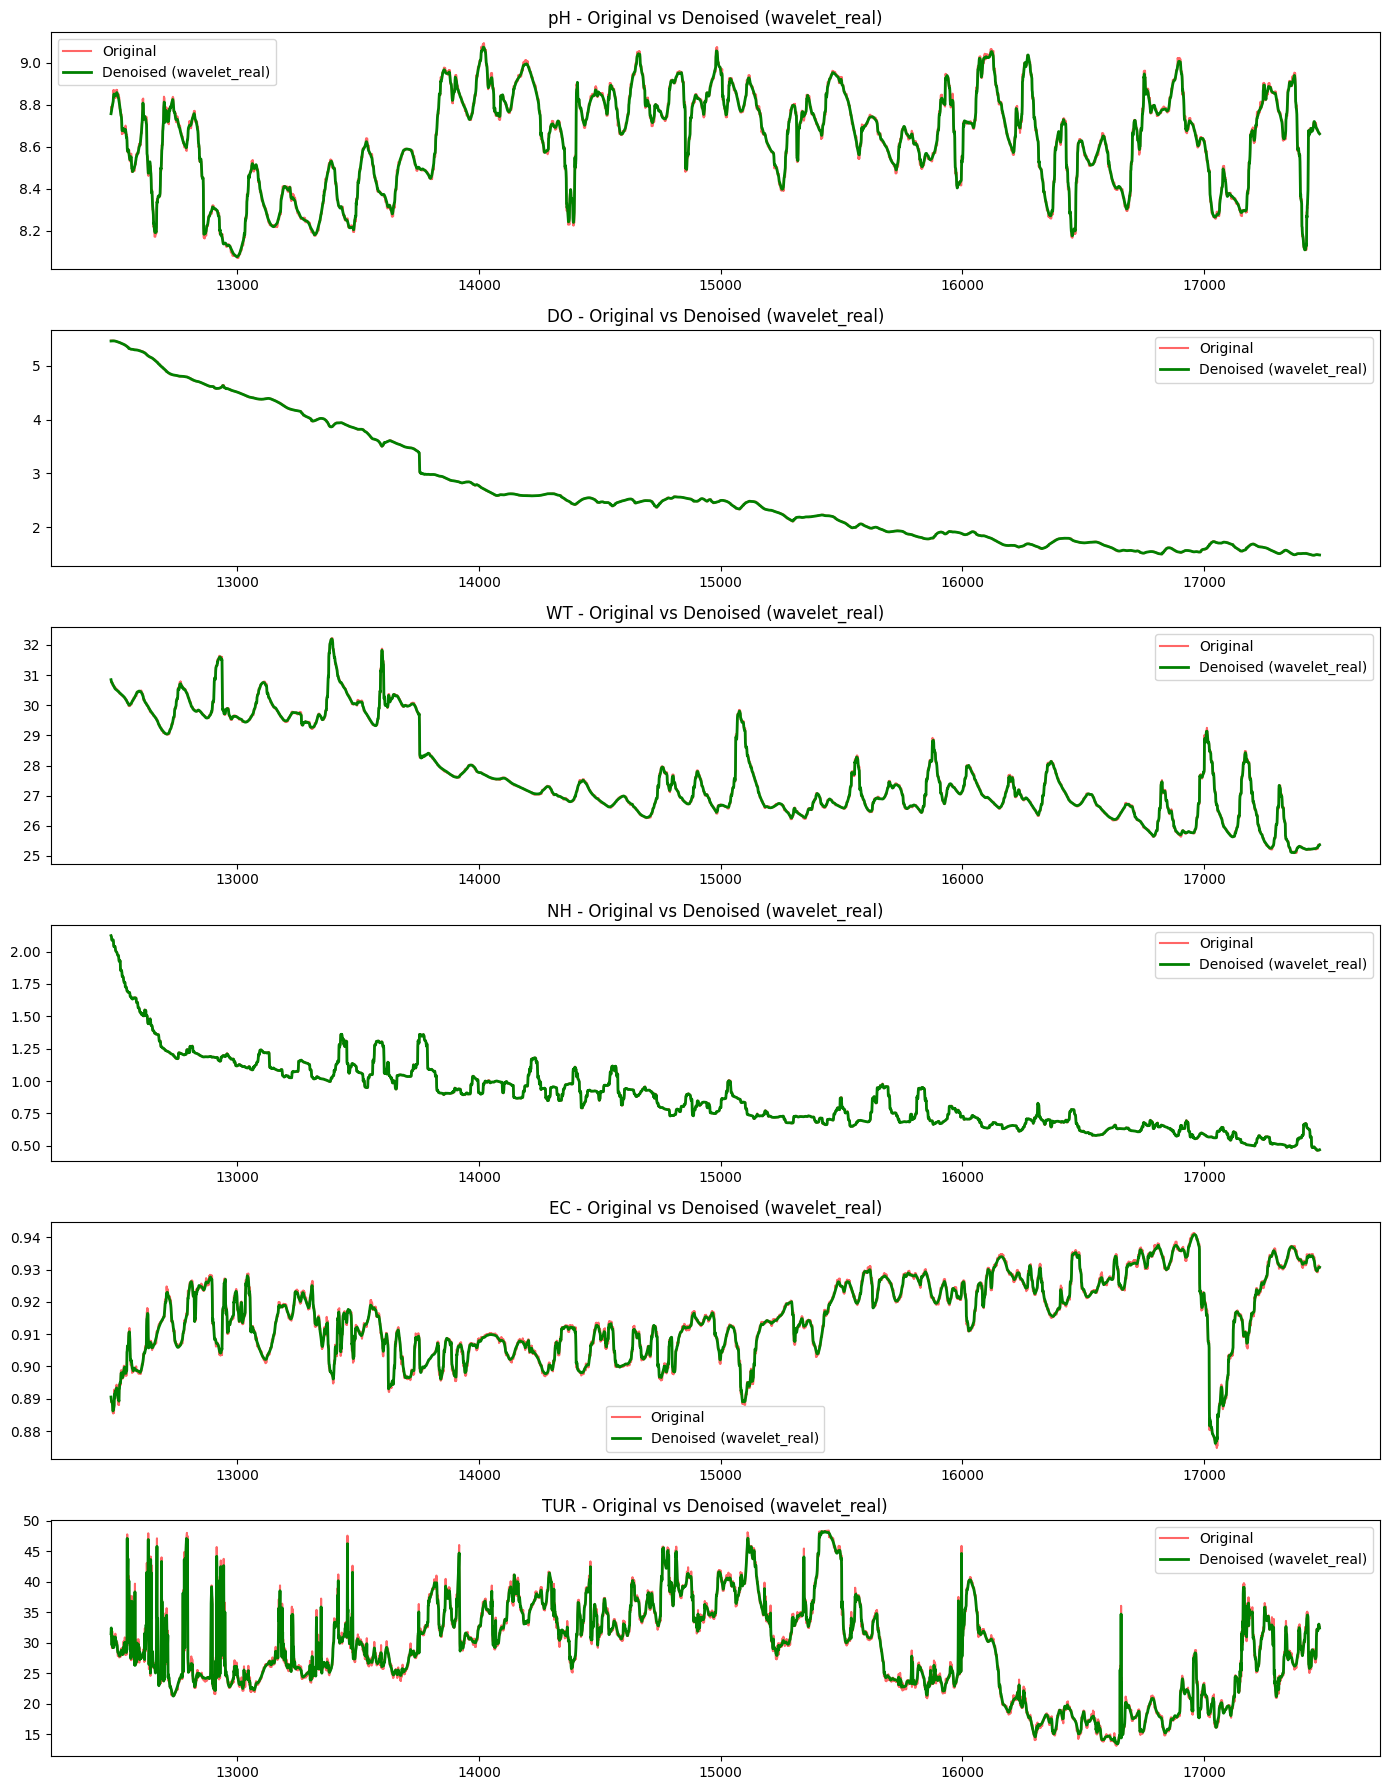

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import PCA
from scipy.ndimage import uniform_filter1d
import pywt
import warnings
warnings.filterwarnings('ignore')


# Butterworth-based denoiser (simple low-pass)
class AdvancedWaveletDenoiser:
    def multi_level_denoising(self, data):
        b, a = signal.butter(4, 0.1, btype='low')
        return signal.filtfilt(b, a, data)


# True wavelet denoiser
class TrueWaveletDenoiser:
    def __init__(self, wavelet='db4', level=None):
        self.wavelet = wavelet
        self.level = level
    
    def multi_level_denoising(self, data):
        coeffs = pywt.wavedec(data, self.wavelet, level=self.level)
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745
        threshold = sigma * np.sqrt(2 * np.log(len(data)))
        coeffs_thresh = [pywt.threshold(c, threshold, mode='soft') for c in coeffs]
        reconstructed = pywt.waverec(coeffs_thresh, self.wavelet)
        if len(reconstructed) < len(data):
            reconstructed = np.pad(reconstructed, (0, len(data)-len(reconstructed)), mode='edge')
        elif len(reconstructed) > len(data):
            reconstructed = reconstructed[:len(data)]
        return reconstructed


class DenoisingBenchmark:
    def __init__(self):
        self.methods = {
            'butterworth': self.butterworth_denoising,
            'wavelet_real': self.real_wavelet_denoising,
            'moving_average': self.moving_average,
            'savgol': self.savitzky_golay,
            'kalman': self.kalman_filter,
            'pca': self.pca_denoising,
            'median': self.median_filter
        }

    # --- Denoising methods ---
    def butterworth_denoising(self, data):
        denoiser = AdvancedWaveletDenoiser()
        return denoiser.multi_level_denoising(data)

    def real_wavelet_denoising(self, data):
        denoiser = TrueWaveletDenoiser(wavelet='db4')
        return denoiser.multi_level_denoising(data)

    def moving_average(self, data, window_size=5):
        return uniform_filter1d(data, size=window_size, mode='nearest')

    def savitzky_golay(self, data, window_length=11, polyorder=3):
        window_length = min(window_length, len(data))
        if window_length % 2 == 0:
            window_length -= 1
        if window_length < 3:
            window_length = 3
        polyorder = min(polyorder, window_length - 1)
        return signal.savgol_filter(data, window_length, polyorder)

    def kalman_filter(self, data):
        n = len(data)
        filtered = np.zeros(n)
        x, P, Q, R = data[0], 1.0, 0.01, 0.1
        for i in range(n):
            x_pred, P_pred = x, P + Q
            K = P_pred / (P_pred + R)
            x = x_pred + K * (data[i] - x_pred)
            P = (1 - K) * P_pred
            filtered[i] = x
        return filtered

    def pca_denoising(self, data, n_components=1):
        try:
            window_size = min(10, len(data)//4)
            if window_size < 2:
                return data
            n_samples = len(data) - window_size + 1
            X = np.zeros((n_samples, window_size))
            for i in range(window_size):
                X[:, i] = data[i:i+n_samples]
            pca = PCA(n_components=min(n_components, window_size))
            X_pca = pca.fit_transform(X)
            X_reconstructed = pca.inverse_transform(X_pca)
            reconstructed = np.zeros(len(data))
            counts = np.zeros(len(data))
            for i in range(window_size):
                reconstructed[i:i+n_samples] += X_reconstructed[:, i]
                counts[i:i+n_samples] += 1
            reconstructed = np.divide(
                reconstructed, counts,
                out=np.zeros_like(reconstructed),
                where=counts != 0
            )
            reconstructed[counts == 0] = data[counts == 0]
            return reconstructed
        except Exception as e:
            print(f"PCA denoising error: {e}")
            return data

    def median_filter(self, data, kernel_size=5):
        if kernel_size % 2 == 0:
            kernel_size += 1
        kernel_size = min(kernel_size, len(data))
        return signal.medfilt(data, kernel_size)

    # --- Evaluation ---
    def evaluate(self, clean_signal, denoised_signal):
        min_len = min(len(clean_signal), len(denoised_signal))
        clean_truncated = clean_signal[:min_len]
        denoised_truncated = denoised_signal[:min_len]

        mse = np.mean((clean_truncated - denoised_truncated) ** 2)
        signal_var = np.var(clean_truncated)
        snr = 10 * np.log10(signal_var / mse) if signal_var > 0 and mse > 0 else float('inf')
        correlation = np.corrcoef(clean_truncated, denoised_truncated)[0, 1] if len(clean_truncated) > 1 else 0
        clean_edges = np.abs(np.diff(clean_truncated))
        denoised_edges = np.abs(np.diff(denoised_truncated))
        min_edge_len = min(len(clean_edges), len(denoised_edges))
        edge_correlation = np.corrcoef(clean_edges[:min_edge_len], denoised_edges[:min_edge_len])[0, 1] if min_edge_len > 1 else 0

        # Additional performance metrics
        raw_noise = np.var(np.diff(clean_truncated))
        denoised_noise = np.var(np.diff(denoised_truncated))
        noise_reduction = raw_noise / denoised_noise if denoised_noise > 0 else np.inf

        raw_peaks, _ = signal.find_peaks(clean_truncated, height=np.mean(clean_truncated)+2*np.std(clean_truncated))
        denoised_peaks, _ = signal.find_peaks(denoised_truncated, height=np.mean(denoised_truncated)+2*np.std(denoised_truncated))
        peak_preservation = len(set(raw_peaks) & set(denoised_peaks)) / max(len(raw_peaks), 1)

        raw_fft = np.fft.fft(clean_truncated)
        denoised_fft = np.fft.fft(denoised_truncated)
        spectral_similarity = np.corrcoef(np.abs(raw_fft), np.abs(denoised_fft))[0, 1]

        return {
            'mse': mse,
            'snr_db': snr,
            'correlation': correlation,
            'edge_preservation': edge_correlation,
            'noise_reduction': noise_reduction,
            'peak_preservation': peak_preservation,
            'spectral_similarity': spectral_similarity
        }


def run_denoising_on_real_data(filepath="./data/water_quality_data.csv"):
    df = pd.read_csv(filepath, parse_dates=["timestamp"])
    df = df.set_index("timestamp").resample("1min").mean().interpolate()

    benchmark = DenoisingBenchmark()
    results = {}

    for col in df.columns:
        series = df[col].values
        results[col] = {}
        for method_name, method in benchmark.methods.items():
            denoised = method(series)
            metrics = benchmark.evaluate(series, denoised)
            results[col][method_name] = {'original': series, 'denoised': denoised, **metrics}

    return df, results

def plot_wavelet_real(df, results, method="wavelet", n_points=2000):
    params = list(results.keys())
    n_params = len(params)
    plt.figure(figsize=(14, 3 * n_params))

    for i, param in enumerate(params, 1):
        plt.subplot(n_params, 1, i)
        indices = np.arange(len(df[param]))[-n_points:]  # last n points
        plt.plot(indices, results[param][method]["original"][-n_points:], 'r-', alpha=0.6, label="Original")
        plt.plot(indices, results[param][method]["denoised"][-n_points:], 'g-', label=f"Denoised ({method})", linewidth=2)
        plt.title(f"{param} - Original vs Denoised ({method})")
        plt.legend()

    plt.tight_layout()
    plt.show()

def plot_all_methods_comparison(df, results, n_points=500):
    params = list(results.keys())
    n_params = len(params)
    methods = list(next(iter(results.values())).keys())
    
    plt.figure(figsize=(16, 3 * n_params))
    
    for i, param in enumerate(params, 1):
        plt.subplot(n_params, 1, i)
        indices = np.arange(len(df[param]))[-n_points:]
        
        # Original signal
        plt.plot(indices, results[param][methods[0]]["original"][-n_points:], 'k--', alpha=0.7, label="Original")
        
        # Plot each method
        colors = ['r', 'g', 'b', 'm', 'c', 'y', 'orange']
        for color, method in zip(colors, methods):
            plt.plot(indices, results[param][method]["denoised"][-n_points:], color=color, label=method, linewidth=1.5)
        
        plt.title(f"{param} - Original vs Denoised (All Methods)")
        plt.legend(ncol=4, fontsize=8)
    
    plt.tight_layout()
    plt.savefig("./output/wavelet_method_comparison.png", dpi=300)
    plt.show()


if __name__ == "__main__":
    df, results = run_denoising_on_real_data()

    print("\n" + "="*80)
    print("COMPREHENSIVE BENCHMARK SUMMARY (Real Data)")
    print("="*80)

    for param in results:
        print(f"\nParameter: {param}")
        for method, metrics in results[param].items():
            print(f"{method:15} | "
                  f"SNR: {metrics['snr_db']:6.2f} dB | "
                  f"Corr: {metrics['correlation']:5.3f} | "
                  f"Edge: {metrics['edge_preservation']:5.3f} | "
                  f"MSE: {metrics['mse']:.6f} | "
                  f"NoiseRed: {metrics['noise_reduction']:.3f} | "
                  f"PeakPres: {metrics['peak_preservation']:.3f} | "
                  f"SpectralSim: {metrics['spectral_similarity']:.3f}")
            
    # Example: Plot wavelet real method
    plot_wavelet_real(df, results, method="wavelet_real", n_points=5000)
    # Plot last 2000 points for comparison
    #plot_all_methods_comparison(df, results, n_points=100)


## 4.9 Operational Deployment Considerations

### 4.9.1 Real-Time Processing Architecture

In [34]:
import asyncio
import json
import numpy as np
from datetime import datetime
import logging
from advance_denoiser import AdvancedWaveletDenoiser

class RealTimeWaterQualityProcessor:
    def __init__(self, config_file='config.json'):
        self.config = self.load_config(config_file)
        self.denoiser = AdvancedWaveletDenoiser()
        self.buffer_size = self.config.get('buffer_size', 100)
        self.data_buffer = {}
        self.alert_thresholds = self.config.get('alert_thresholds', {})
        
        # Setup logging
        logging.basicConfig(level=logging.INFO)
        self.logger = logging.getLogger(__name__)
        
    def load_config(self, config_file):
        """Load system configuration"""
        try:
            with open(config_file, 'r') as f:
                return json.load(f)
        except FileNotFoundError:
            return self.get_default_config()
    
    def get_default_config(self):
        """Default configuration"""
        return {
            'buffer_size': 100,
            'processing_interval': 60,  # seconds
            'alert_thresholds': {
                'pH': {'min': 6.5, 'max': 8.5},
                'DO': {'min': 5.0, 'max': 15.0},
                'COD': {'min': 0, 'max': 15.0},
                'EC': {'min': 0, 'max': 1500},
                'NH': {'min': 0, 'max': 0.5},
                'TUR': {'min': 0, 'max': 4.0},
                'WT': {'min': 0, 'max': 25}
            }
        }
    
    async def process_sensor_data(self, sensor_id, parameter, value, timestamp):
        """Process incoming sensor data in real-time"""
        
        # Initialize buffer for new sensor/parameter combinations
        key = f"{sensor_id}_{parameter}"
        if key not in self.data_buffer:
            self.data_buffer[key] = []
        
        # Add new data point
        self.data_buffer[key].append({
            'timestamp': timestamp,
            'value': value
        })
        
        # Maintain buffer size
        if len(self.data_buffer[key]) > self.buffer_size:
            self.data_buffer[key].pop(0)
        
        # Process when buffer is sufficiently full
        if len(self.data_buffer[key]) >= 50:  # Minimum for wavelet processing
            await self.process_buffer(sensor_id, parameter)
    
    async def process_buffer(self, sensor_id, parameter):
        """Process buffered data with wavelet denoising"""
        key = f"{sensor_id}_{parameter}"
        buffer_data = self.data_buffer[key]
        
        # Extract values for processing
        values = np.array([point['value'] for point in buffer_data])
        timestamps = [point['timestamp'] for point in buffer_data]
        
        # Apply denoising
        try:
            denoised_values = self.denoiser.parameter_optimized_denoising(
                values, parameter
            )
            
            # Get the most recent denoised value
            latest_denoised = denoised_values[-1]
            latest_timestamp = timestamps[-1]
            
            # Check for anomalies/alerts
            await self.check_alerts(
                sensor_id, parameter, latest_denoised, latest_timestamp
            )
            
            # Store/forward processed data
            await self.store_processed_data(
                sensor_id, parameter, latest_denoised, latest_timestamp
            )
            
        except Exception as e:
            self.logger.error(f"Error processing {key}: {e}")
    
    async def check_alerts(self, sensor_id, parameter, value, timestamp):
        """Check for alert conditions"""
        if parameter in self.alert_thresholds:
            thresholds = self.alert_thresholds[parameter]
            
            if value < thresholds['min'] or value > thresholds['max']:
                alert = {
                    'sensor_id': sensor_id,
                    'parameter': parameter,
                    'value': value,
                    'timestamp': timestamp,
                    'alert_type': 'threshold_violation',
                    'severity': 'HIGH' if (
                        value < thresholds['min'] * 0.8 or 
                        value > thresholds['max'] * 1.2
                    ) else 'MEDIUM'
                }
                
                await self.send_alert(alert)
    
    async def send_alert(self, alert):
        """Send alert notification"""
        self.logger.warning(f"ALERT: {alert}")
        
        # Here you would integrate with your alert system
        # e.g., email, SMS, dashboard notifications, etc.
        
    async def store_processed_data(self, sensor_id, parameter, value, timestamp):
        """Store processed data to database/data lake"""
        # Implement your data storage logic here
        self.logger.info(f"Stored: {sensor_id}/{parameter} = {value:.3f} at {timestamp}")

# Example usage
async def main():
    processor = RealTimeWaterQualityProcessor()
    
    # Simulate incoming sensor data
    while True:
        # This would be replaced with actual sensor data ingestion
        await processor.process_sensor_data(
            sensor_id='MLR_001',
            parameter='pH',
            value=7.2 + 0.1 * np.random.randn(),
            timestamp=datetime.now()
        )
        
        await asyncio.sleep(60)  # Process every minute

# Run the processor
# asyncio.run(main())
# await main() # run in jupyter notebook

In [35]:
# Example usage
async def main():
    processor = RealTimeWaterQualityProcessor()
    
    # Run for 10 samples instead of forever
    for i in range(10):
        await processor.process_sensor_data(
            sensor_id='MLR_001',
            parameter='pH',
            value=7.2 + 0.1 * np.random.randn(),
            timestamp=datetime.now()
        )
        
        await asyncio.sleep(2)  # shorter delay for demo, change to 60s if needed

    print("✅ Finished 10 cycles of processing")

await main() # run in jupyter notebook

✅ Finished 10 cycles of processing


### 4.9.2 Scalability and Performance Optimization

In [43]:
class ScalableWaterQualitySystem:
    def __init__(self):
        self.processing_queue = asyncio.Queue()
        self.worker_pool_size = 4
        self.batch_size = 100
        
    async def batch_processor(self):
        """Process data in batches for efficiency"""
        batch = []
        
        while True:
            try:
                # Collect batch
                while len(batch) < self.batch_size:
                    data_point = await asyncio.wait_for(
                        self.processing_queue.get(), timeout=1.0
                    )
                    batch.append(data_point)
                
                # Process batch
                await self.process_batch(batch)
                batch.clear()
                
            except asyncio.TimeoutError:
                # Process partial batch if timeout
                if batch:
                    await self.process_batch(batch)
                    batch.clear()
    
    async def process_batch(self, batch):
        """Process a batch of data points"""
        # Group by parameter type for efficient processing
        parameter_groups = {}
        
        for data_point in batch:
            param = data_point['parameter']
            if param not in parameter_groups:
                parameter_groups[param] = []
            parameter_groups[param].append(data_point)
        
        # Process each parameter group
        tasks = []
        for parameter, data_points in parameter_groups.items():
            task = self.process_parameter_group(parameter, data_points)
            tasks.append(task)
        
        await asyncio.gather(*tasks)
    
    async def process_parameter_group(self, parameter, data_points):
        """Process all data points for a specific parameter"""
        # Extract values and apply batch denoising
        values = np.array([dp['value'] for dp in data_points])
        
        denoiser = AdvancedWaveletDenoiser()
        denoised_values = denoiser.parameter_optimized_denoising(
            values, parameter
        )
        
        # Update data points with denoised values
        for i, data_point in enumerate(data_points):
            data_point['denoised_value'] = denoised_values[i]
            await self.handle_processed_data(data_point)

Example Usage

In [45]:
import asyncio
import pandas as pd
import numpy as np

# Assume AdvancedWaveletDenoiser is defined/imported
#from scalable_system import ScalableWaterQualitySystem 
#from water_denoiser import AdvancedWaveletDenoiser  

async def main():
    # Load water quality data
    df = pd.read_csv("./data/water_quality_data.csv", parse_dates=["timestamp"])
    df = df.set_index("timestamp").resample("1min").mean().interpolate()

    # Initialize the scalable system
    system = ScalableWaterQualitySystem()

    # Start batch processor in the background
    processor_task = asyncio.create_task(system.batch_processor())

    # Enqueue all data points
    for timestamp, row in df.iterrows():
        for parameter in df.columns:
            data_point = {
                "timestamp": timestamp,
                "parameter": parameter,
                "value": row[parameter]
            }
            await system.processing_queue.put(data_point)

    # Wait a bit for processing to complete
    await asyncio.sleep(2)  # adjust based on dataset size

    # Cancel the processor task (for demo purposes)
    processor_task.cancel()
    try:
        await processor_task
    except asyncio.CancelledError:
        pass

# Example handle_processed_data implementation
def patch_handle_processed_data():
    async def handle_processed_data(self, data_point):
        # For testing, just print the denoised value
        print(f"{data_point['timestamp']} | {data_point['parameter']} | {data_point['denoised_value']:.4f}")
    ScalableWaterQualitySystem.handle_processed_data = handle_processed_data

# Patch the method for demo
patch_handle_processed_data()

# Run the async main
asyncio.run(main())


2019-05-06 14:58:00 | pH | 8.1651
2019-05-06 14:59:00 | pH | 8.1666
2019-05-06 15:00:00 | pH | 8.1677
2019-05-06 15:01:00 | pH | 8.1685
2019-05-06 15:02:00 | pH | 8.1688
2019-05-06 15:03:00 | pH | 8.1691
2019-05-06 15:04:00 | pH | 8.1694
2019-05-06 15:05:00 | pH | 8.1700
2019-05-06 15:06:00 | pH | 8.1706
2019-05-06 15:07:00 | pH | 8.1707
2019-05-06 15:08:00 | pH | 8.1705
2019-05-06 15:09:00 | pH | 8.1702
2019-05-06 15:10:00 | pH | 8.1694
2019-05-06 15:11:00 | pH | 8.1679
2019-05-06 15:12:00 | pH | 8.1663
2019-05-06 15:13:00 | pH | 8.1656
2019-05-06 15:14:00 | pH | 8.1653
2019-05-06 14:58:00 | DO | 12.6510
2019-05-06 14:59:00 | DO | 12.6552
2019-05-06 15:00:00 | DO | 12.6577
2019-05-06 15:01:00 | DO | 12.6509
2019-05-06 15:02:00 | DO | 12.6426
2019-05-06 15:03:00 | DO | 12.6555
2019-05-06 15:04:00 | DO | 12.7014
2019-05-06 15:05:00 | DO | 12.7686
2019-05-06 15:06:00 | DO | 12.7851
2019-05-06 15:07:00 | DO | 12.8014
2019-05-06 15:08:00 | DO | 12.7927
2019-05-06 15:09:00 | DO | 12.7844
20

## 4.10 Advanced Features and Extensions

### 4.10.1 Machine Learning Integration

Creating sample water quality data...
Sample data created successfully!
Data shape: (8737, 6)
Date range: 2019-01-01 00:00:00 to 2019-12-31 00:00:00

TRAINING MODELS FOR PARAMETER COMPARISON

Training model for pH
=== TRAINING MODEL FOR pH ===

Created 8713 sequences with 13 features
Training samples: 5576
Validation samples: 1394
Test samples: 1743
Model saved: ./models\water_quality_pH_20250926_201324.pth
Model saved: ./models\water_quality_pH_20250926_201328.pth
Model saved: ./models\water_quality_pH_20250926_201332.pth
Epoch [10/50], Train Loss: 0.069391, Val Loss: 0.032039
Model saved: ./models\water_quality_pH_20250926_201346.pth
Model saved: ./models\water_quality_pH_20250926_201348.pth
Epoch [20/50], Train Loss: 0.067884, Val Loss: 0.035726
Early stopping at epoch 24

=== RESULTS FOR pH ===
MSE: 0.0158
MAE: 0.0996
RMSE: 0.1259
R2: 0.8975
MAPE: 1.3273
Correlation: 0.9556
Training plot: ./output/pH_training_20250926_201406.png


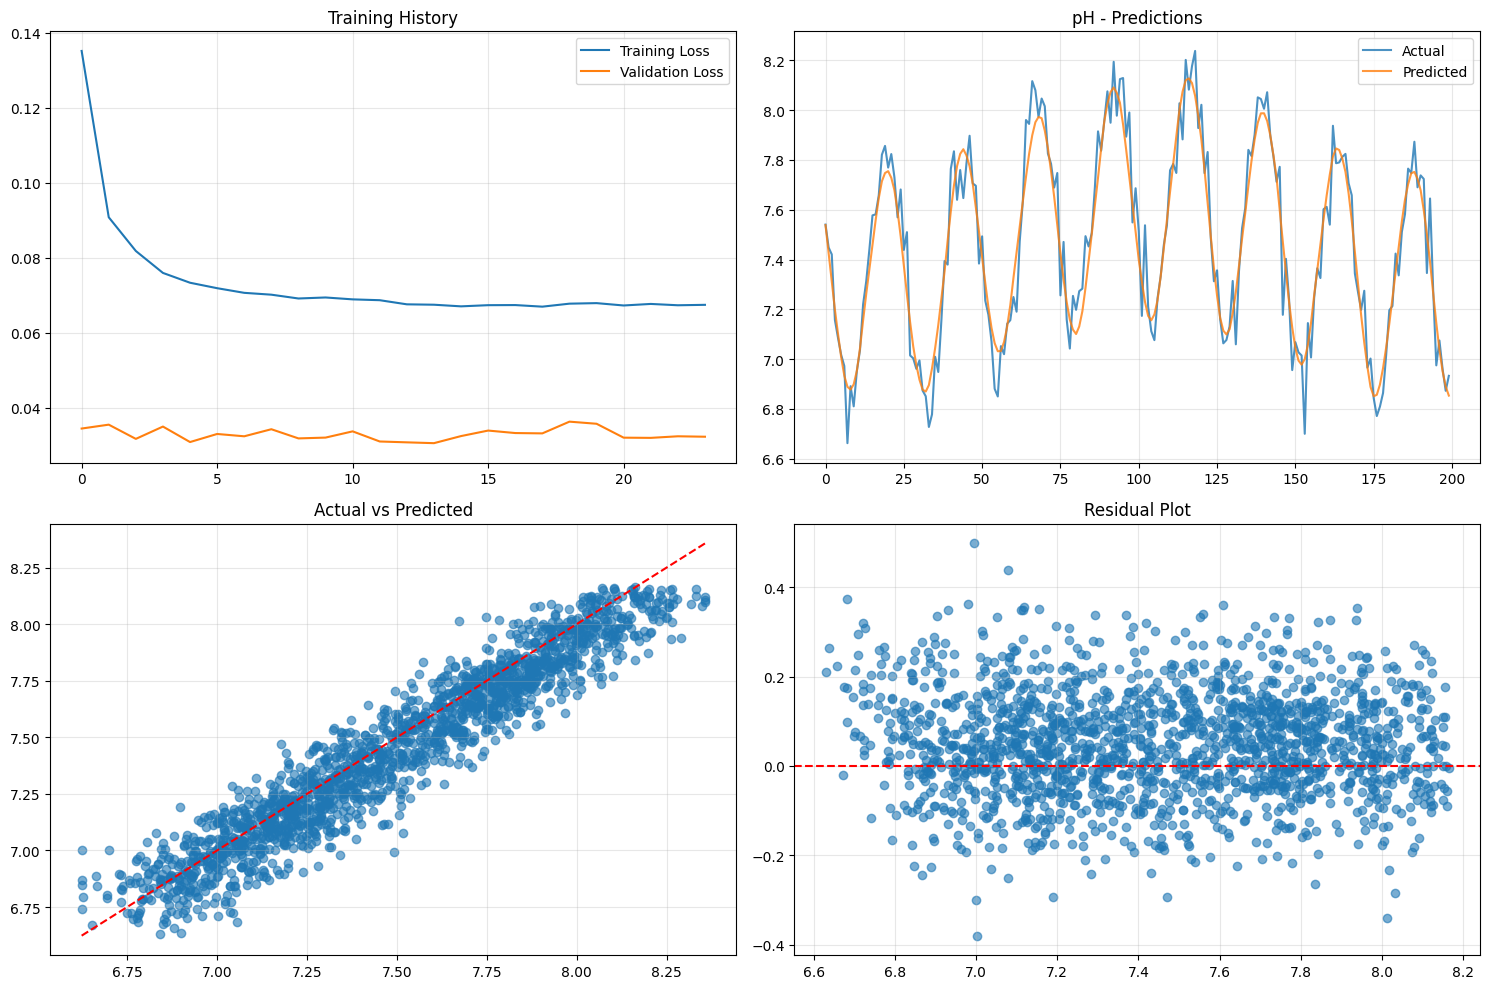

Training report: ./output/pH_report_20250926_201407.json
Metrics CSV: ./output/pH_metrics_20250926_201407.csv

Training model for DO
=== TRAINING MODEL FOR DO ===

Created 8713 sequences with 13 features
Training samples: 5576
Validation samples: 1394
Test samples: 1743
Model saved: ./models\water_quality_DO_20250926_201409.pth
Model saved: ./models\water_quality_DO_20250926_201411.pth
Model saved: ./models\water_quality_DO_20250926_201413.pth
Model saved: ./models\water_quality_DO_20250926_201415.pth
Epoch [10/50], Train Loss: 0.139326, Val Loss: 0.087656
Early stopping at epoch 14

=== RESULTS FOR DO ===
MSE: 0.0470
MAE: 0.1729
RMSE: 0.2167
R2: 0.7974
MAPE: 2.1676
Correlation: 0.8988
Training plot: ./output/DO_training_20250926_201432.png


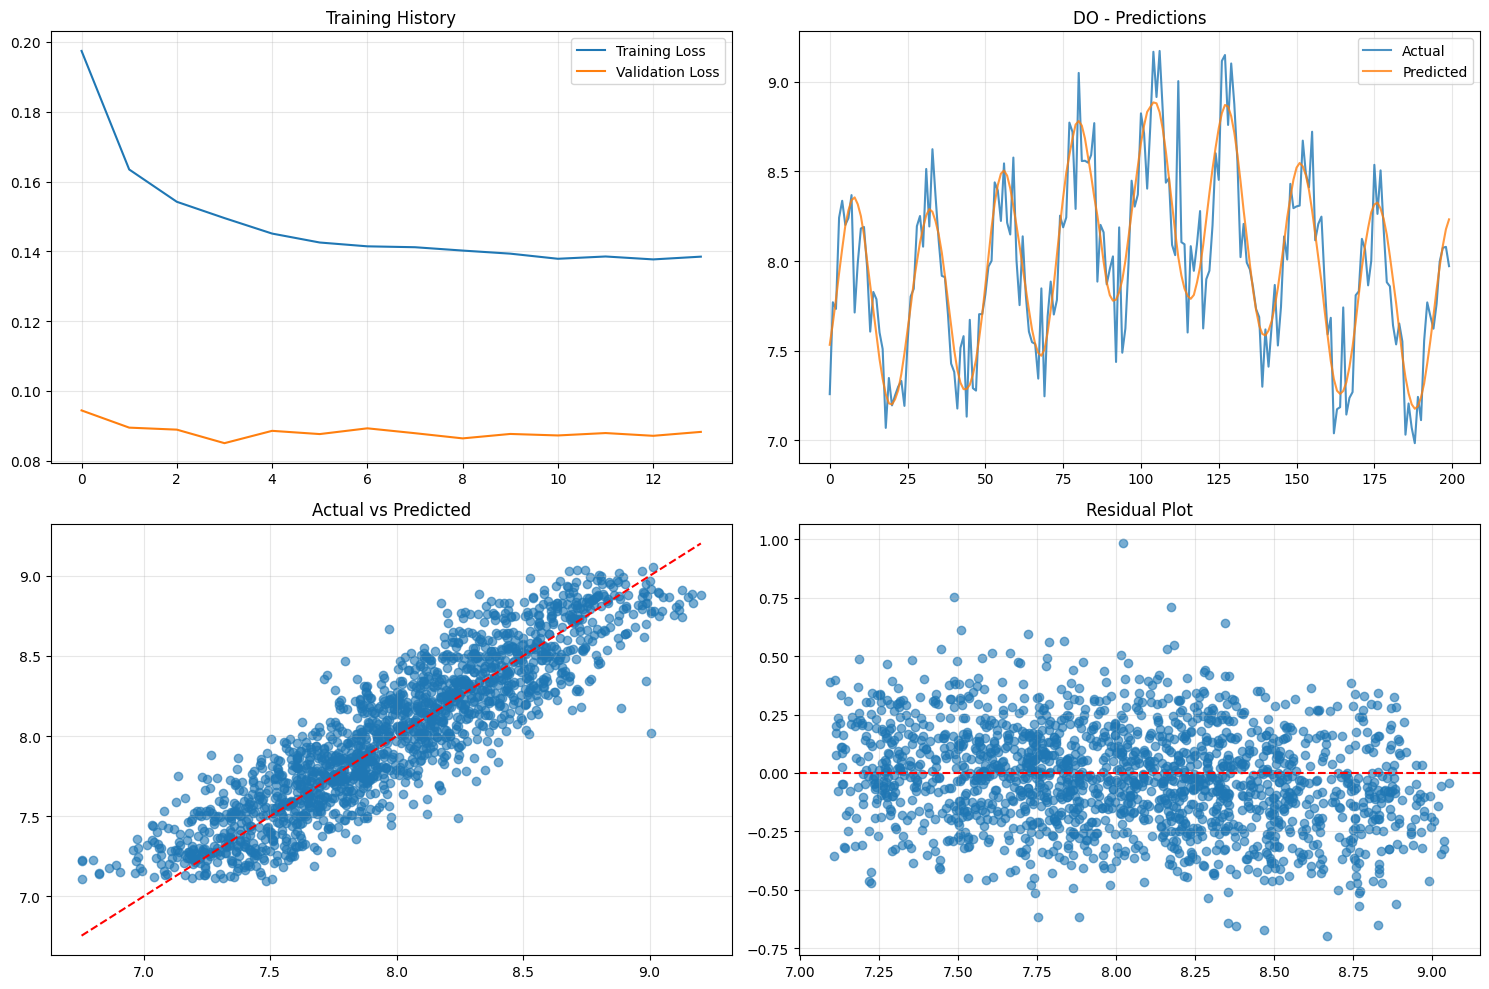

Training report: ./output/DO_report_20250926_201433.json
Metrics CSV: ./output/DO_metrics_20250926_201433.csv

Training model for WT
=== TRAINING MODEL FOR WT ===

Created 8713 sequences with 13 features
Training samples: 5576
Validation samples: 1394
Test samples: 1743
Model saved: ./models\water_quality_WT_20250926_201435.pth
Epoch [10/50], Train Loss: 0.167504, Val Loss: 0.958492
Early stopping at epoch 11

=== RESULTS FOR WT ===
MSE: 64.4026
MAE: 7.6873
RMSE: 8.0251
R2: -8.0495
MAPE: 53.4473
Correlation: 0.5092
Training plot: ./output/WT_training_20250926_201453.png


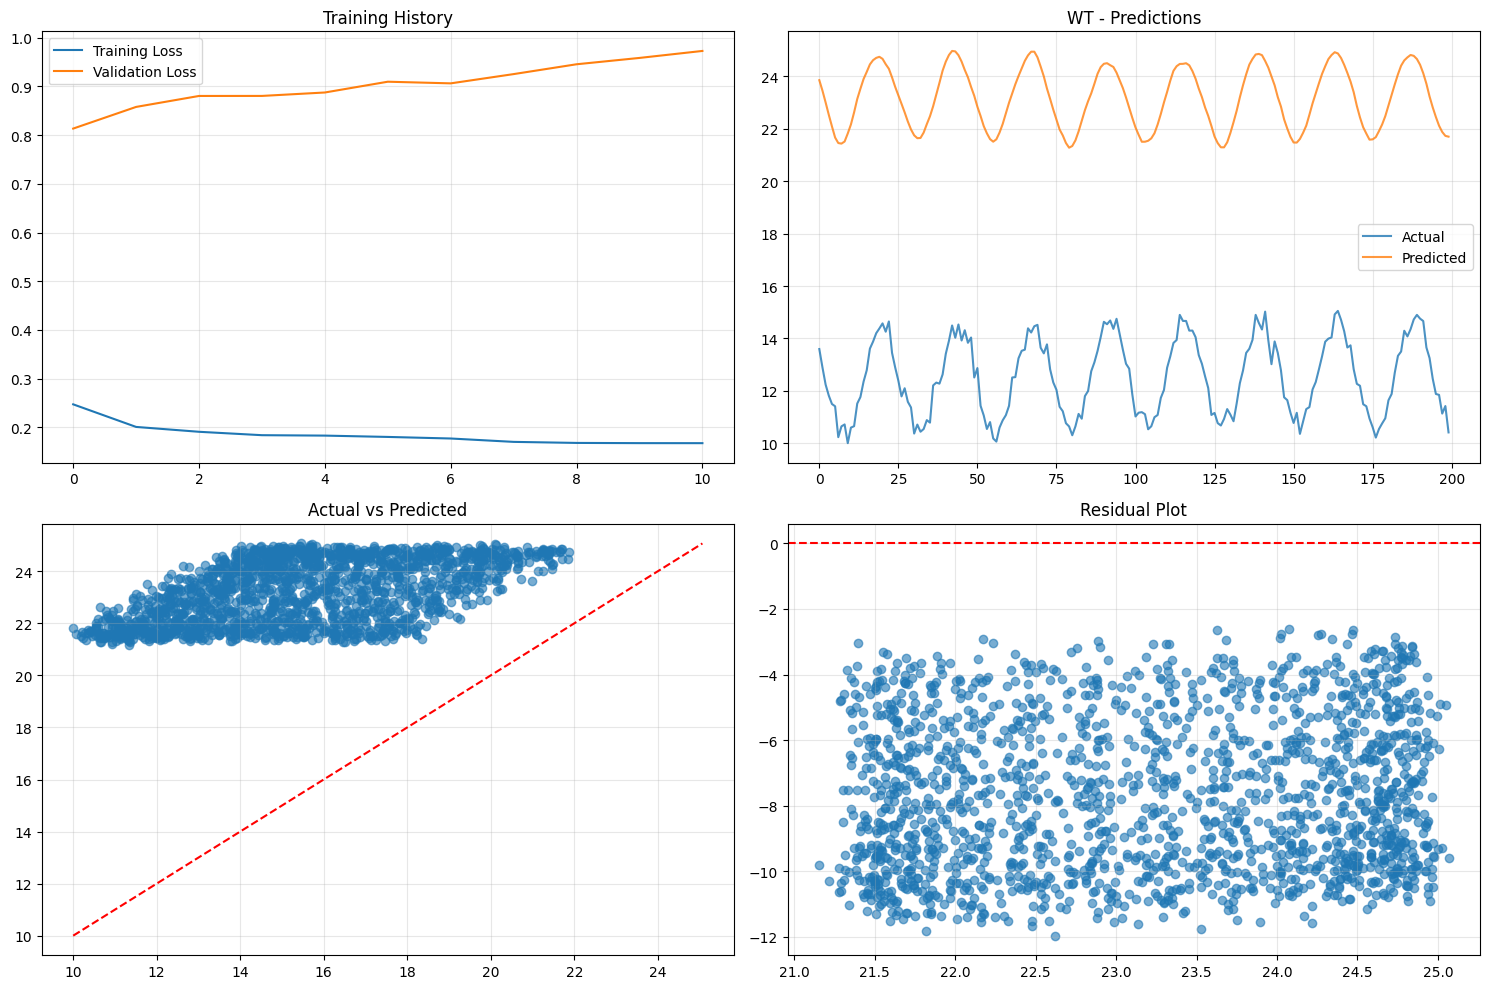

Training report: ./output/WT_report_20250926_201454.json
Metrics CSV: ./output/WT_metrics_20250926_201454.csv

Training model for NH
=== TRAINING MODEL FOR NH ===

Created 8713 sequences with 13 features
Training samples: 5576
Validation samples: 1394
Test samples: 1743
Model saved: ./models\water_quality_NH_20250926_201456.pth
Model saved: ./models\water_quality_NH_20250926_201458.pth
Model saved: ./models\water_quality_NH_20250926_201500.pth
Model saved: ./models\water_quality_NH_20250926_201505.pth
Epoch [10/50], Train Loss: 0.145510, Val Loss: 0.151684
Early stopping at epoch 16

=== RESULTS FOR NH ===
MSE: 0.0028
MAE: 0.0427
RMSE: 0.0533
R2: 0.6442
MAPE: 16.3809
Correlation: 0.8071
Training plot: ./output/NH_training_20250926_201524.png


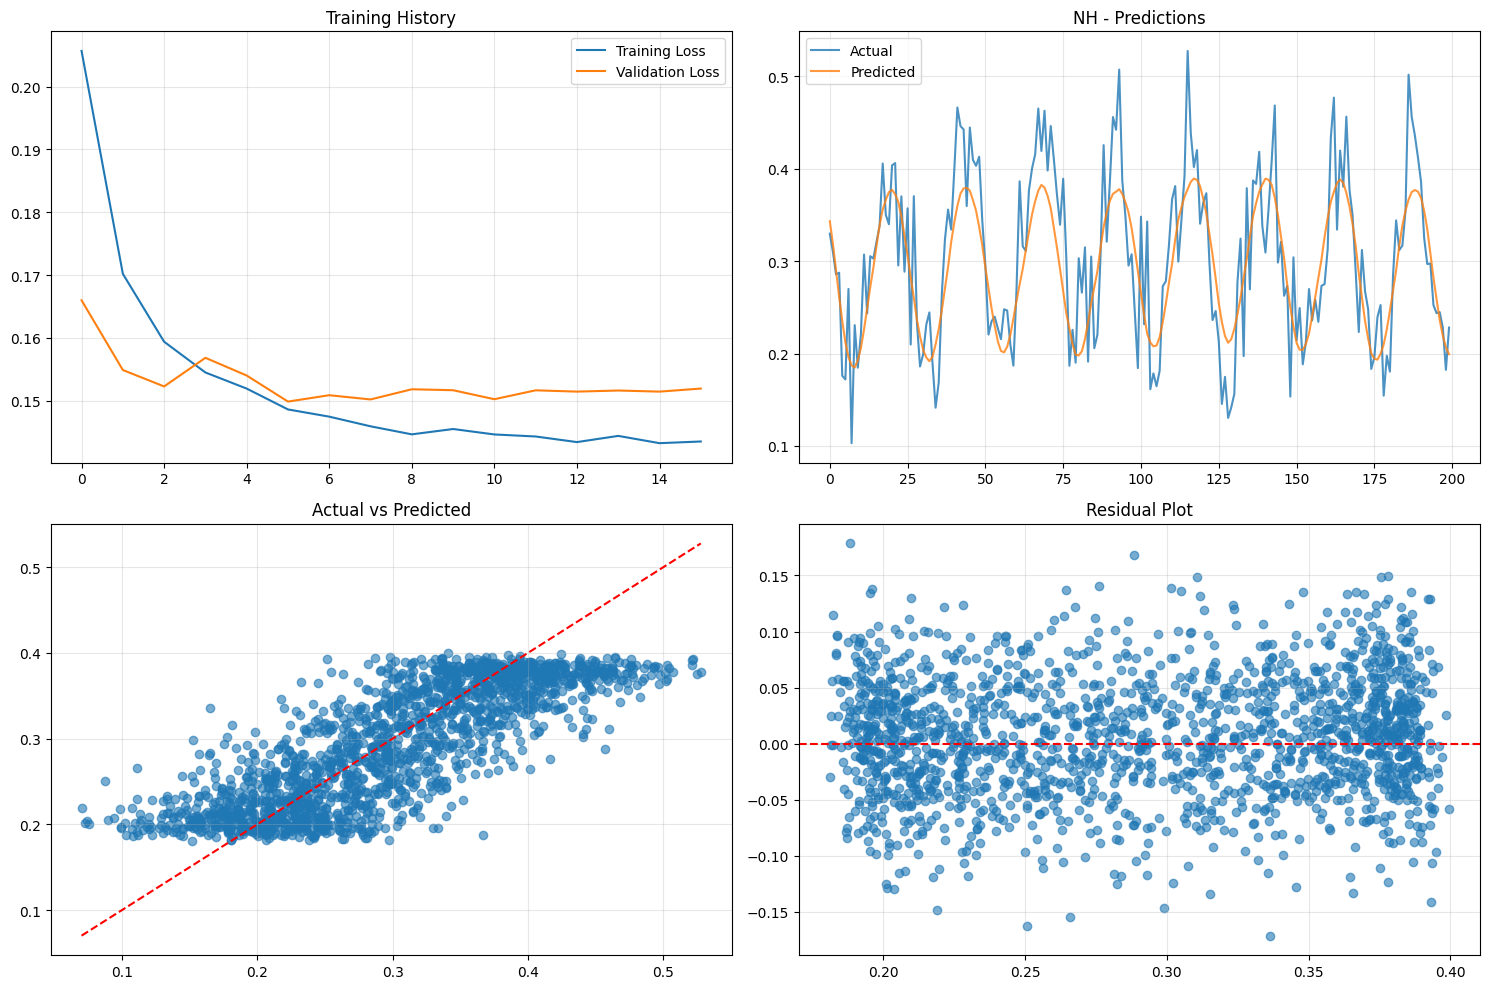

Training report: ./output/NH_report_20250926_201525.json
Metrics CSV: ./output/NH_metrics_20250926_201525.csv

PARAMETER COMPARISON SUMMARY
                 pH      DO       WT       NH
R²           0.8975  0.7974  -8.0495   0.6442
RMSE         0.1259  0.2167   8.0251   0.0533
MAE          0.0996  0.1729   7.6873   0.0427
MAPE (%)     1.3273  2.1676  53.4473  16.3809
Correlation  0.9556  0.8988   0.5092   0.8071


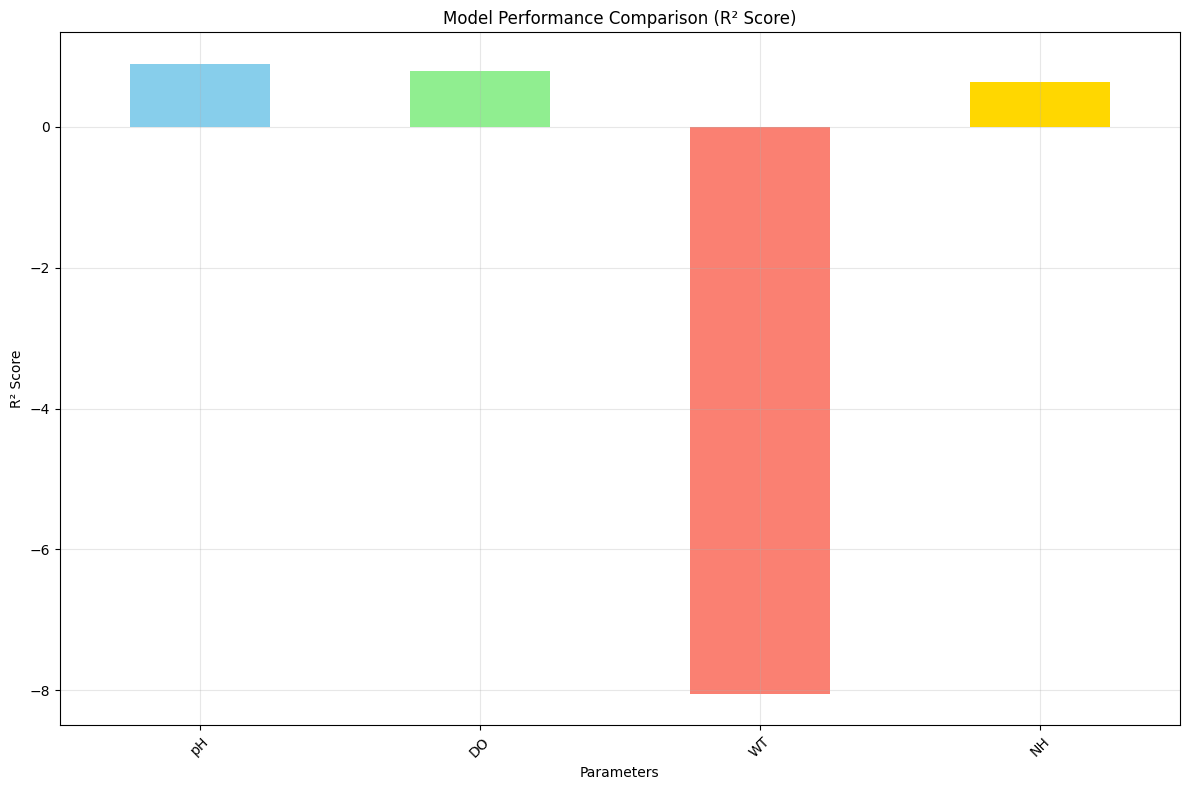


Comparison files saved:
- CSV: ./output/parameter_comparison_20250926_201525.csv
- Plot: ./output/parameter_comparison_plot_20250926_201525.png

MODEL MANAGEMENT
pH: 5 models available
  Best model: 20250926_201348, Loss: 0.030554
DO: 4 models available
  Best model: 20250926_201415, Loss: 0.085015
NH: 4 models available
  Best model: 20250926_201505, Loss: 0.149875

FORECASTING DEMONSTRATION

Generating forecast for pH...
Model loaded from: ./models\water_quality_pH_20250926_201348.pth
Validation loss: 0.030554
Forecasting error for pH: keys must be str, int, float, bool or None, not Timestamp

Generating forecast for DO...
Model loaded from: ./models\water_quality_DO_20250926_201415.pth
Validation loss: 0.085015
Forecasting error for DO: keys must be str, int, float, bool or None, not Timestamp

Generating forecast for NH...
Model loaded from: ./models\water_quality_NH_20250926_201505.pth
Validation loss: 0.149875
Forecasting error for NH: keys must be str, int, float, bool or None,

In [ ]:

import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import pickle
import json
import os
import glob
from water_denoiser import AdvancedWaveletDenoiser
import warnings
warnings.filterwarnings('ignore')

class WaterQualityLSTM(nn.Module):
    """Simplified LSTM model focused on single-step forecasting"""
    
    def __init__(self, input_size, hidden_size=64, num_layers=2, output_size=1, dropout=0.1):
        super(WaterQualityLSTM, self).__init__()
        
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(
            input_size, hidden_size, num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0
        )
        
        self.batch_norm = nn.BatchNorm1d(hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        lstm_out, (hidden, cell) = self.lstm(x)
        last_output = lstm_out[:, -1, :]
        out = self.batch_norm(last_output)
        out = self.dropout(out)
        out = self.fc(out)
        return out

class WaterQualityPipeline:
    """Enhanced ML pipeline with integrated wavelet denoising and hyperparameter tuning"""
    
    def __init__(self, target_parameter='pH', sequence_length=24, model_dir="./models", use_denoising=True):
        self.target_parameter = target_parameter
        self.sequence_length = sequence_length
        self.model_dir = model_dir
        self.use_denoising = use_denoising
        self.denoiser = AdvancedWaveletDenoiser() if use_denoising else None
        self.feature_scaler = RobustScaler()
        self.target_scaler = RobustScaler()
        self.model = None
        self.feature_columns = None
        self.best_model_path = None
        self.best_val_loss = float('inf')
        self.denoising_stats = {}
        os.makedirs(model_dir, exist_ok=True)
        os.makedirs("./output", exist_ok=True)
    
    def apply_wavelet_denoising(self, df):
        if not self.use_denoising or self.denoiser is None:
            return df.copy(), {}
        print("Applying wavelet denoising...")
        df_denoised, noise_stats = self.denoiser.denoise_dataframe(df)
        self.denoising_stats = noise_stats
        print("\nDenoising Results (Noise Reduction Ratio):")
        for param, ratio in noise_stats.items():
            print(f"  {param}: {ratio:.4f} (lower is better)")
        return df_denoised, noise_stats
    
    def save_model_and_metadata(self, val_loss, epoch, metadata=None):
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        model_name = f"water_quality_{self.target_parameter}_{timestamp}.pth"
        model_path = os.path.join(self.model_dir, model_name)
        
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'model_architecture': {
                'input_size': self.model.lstm.input_size,
                'hidden_size': self.model.hidden_size,
                'num_layers': self.model.num_layers,
                'output_size': self.model.fc.out_features
            },
            'val_loss': val_loss,
            'epoch': epoch,
            'timestamp': timestamp,
            'target_parameter': self.target_parameter,
            'use_denoising': self.use_denoising
        }, model_path)
        
        feature_scaler_path = os.path.join(self.model_dir, f"feature_scaler_{self.target_parameter}_{timestamp}.pkl")
        target_scaler_path = os.path.join(self.model_dir, f"target_scaler_{self.target_parameter}_{timestamp}.pkl")
        
        with open(feature_scaler_path, 'wb') as f:
            pickle.dump(self.feature_scaler, f)
        with open(target_scaler_path, 'wb') as f:
            pickle.dump(self.target_scaler, f)
        
        metadata_dict = {
            'target_parameter': self.target_parameter,
            'feature_columns': self.feature_columns,
            'sequence_length': self.sequence_length,
            'model_path': model_path,
            'feature_scaler_path': feature_scaler_path,
            'target_scaler_path': target_scaler_path,
            'val_loss': val_loss,
            'epoch': epoch,
            'timestamp': timestamp,
            'use_denoising': self.use_denoising,
            'denoising_stats': self.denoising_stats,
            'model_architecture': {
                'input_size': self.model.lstm.input_size,
                'hidden_size': self.model.hidden_size,
                'num_layers': self.model.num_layers,
                'output_size': self.model.fc.out_features
            }
        }
        if metadata:
            metadata_dict.update(metadata)
        
        metadata_path = os.path.join(self.model_dir, f"metadata_{self.target_parameter}_{timestamp}.json")
        with open(metadata_path, 'w') as f:
            json.dump(metadata_dict, f, indent=2)
        
        print(f"Model saved: {model_path}")
        return model_path, metadata_path
    
    def load_model(self, model_path=None):
        """Fixed model loading with proper architecture matching"""
        if model_path is None:
            # Find the latest model for this parameter
            model_files = [f for f in os.listdir(self.model_dir) 
                          if f.startswith(f"water_quality_{self.target_parameter}_") and f.endswith(".pth")]
            if not model_files:
                raise FileNotFoundError(f"No saved models found for parameter {self.target_parameter}")
            
            # Sort by timestamp (newest first)
            model_files.sort(reverse=True)
            model_path = os.path.join(self.model_dir, model_files[0])
            
            # Extract timestamp from filename
            timestamp = model_files[0].replace(f"water_quality_{self.target_parameter}_", "").replace(".pth", "")
            metadata_path = os.path.join(self.model_dir, f"metadata_{self.target_parameter}_{timestamp}.json")
        else:
            # Extract timestamp from provided model path
            base_name = os.path.basename(model_path)
            timestamp = base_name.replace(f"water_quality_{self.target_parameter}_", "").replace(".pth", "")
            metadata_path = os.path.join(os.path.dirname(model_path), f"metadata_{self.target_parameter}_{timestamp}.json")
        
        # Load checkpoint
        checkpoint = torch.load(model_path, map_location='cpu')
        
        # Get architecture from checkpoint (preferred) or metadata
        if 'model_architecture' in checkpoint:
            model_arch = checkpoint['model_architecture']
        else:
            # Fallback to metadata file
            if os.path.exists(metadata_path):
                with open(metadata_path, 'r') as f:
                    metadata = json.load(f)
                model_arch = metadata.get('model_architecture', {
                    'input_size': 18,  # Default fallback
                    'hidden_size': 64,
                    'num_layers': 2,
                    'output_size': 1
                })
            else:
                raise FileNotFoundError(f"Cannot find model architecture information for {model_path}")
        
        # Create model with correct architecture
        self.model = WaterQualityLSTM(
            input_size=model_arch['input_size'],
            hidden_size=model_arch['hidden_size'],
            num_layers=model_arch['num_layers'],
            output_size=model_arch['output_size']
        )
        
        # Load state dict
        try:
            self.model.load_state_dict(checkpoint['model_state_dict'])
            self.model.eval()
        except RuntimeError as e:
            print(f"Error loading model state: {e}")
            print(f"Checkpoint architecture: {model_arch}")
            raise
        
        # Load metadata
        if os.path.exists(metadata_path):
            with open(metadata_path, 'r') as f:
                metadata = json.load(f)
            
            self.feature_columns = metadata['feature_columns']
            self.sequence_length = metadata['sequence_length']
            self.use_denoising = metadata.get('use_denoising', False)
            self.denoising_stats = metadata.get('denoising_stats', {})
            
            # Initialize denoiser if needed
            if self.use_denoising and self.denoiser is None:
                self.denoiser = AdvancedWaveletDenoiser()
            
            # Load scalers
            with open(metadata['feature_scaler_path'], 'rb') as f:
                self.feature_scaler = pickle.load(f)
            with open(metadata['target_scaler_path'], 'rb') as f:
                self.target_scaler = pickle.load(f)
        else:
            print(f"Warning: Metadata file not found at {metadata_path}")
            print("Using default settings - this may cause issues")
        
        print(f"Model loaded from: {model_path}")
        print(f"Architecture: input={model_arch['input_size']}, hidden={model_arch['hidden_size']}, layers={model_arch['num_layers']}")
        print(f"Validation loss: {checkpoint['val_loss']:.6f}")
        print(f"Denoising enabled: {self.use_denoising}")
        return metadata if os.path.exists(metadata_path) else None
    
    def save_scalers_separately(self, suffix=""):
        """Save scalers separately for future use with clear naming"""
        if self.feature_scaler is None or self.target_scaler is None:
            print("Warning: Scalers not fitted yet")
            return None, None
        
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        suffix = f"_{suffix}" if suffix else ""
        
        feature_scaler_path = os.path.join(self.model_dir, f"feature_scaler_{self.target_parameter}{suffix}_{timestamp}.pkl")
        target_scaler_path = os.path.join(self.model_dir, f"target_scaler_{self.target_parameter}{suffix}_{timestamp}.pkl")
        
        with open(feature_scaler_path, 'wb') as f:
            pickle.dump(self.feature_scaler, f)
        with open(target_scaler_path, 'wb') as f:
            pickle.dump(self.target_scaler, f)
        
        # Also save a copy with the latest name for easy access
        latest_feature_path = os.path.join(self.model_dir, f"latest_feature_scaler_{self.target_parameter}.pkl")
        latest_target_path = os.path.join(self.model_dir, f"latest_target_scaler_{self.target_parameter}.pkl")
        
        with open(latest_feature_path, 'wb') as f:
            pickle.dump(self.feature_scaler, f)
        with open(latest_target_path, 'wb') as f:
            pickle.dump(self.target_scaler, f)
        
        print(f"Scalers saved:")
        print(f"  Feature scaler: {feature_scaler_path}")
        print(f"  Target scaler: {target_scaler_path}")
        print(f"  Latest copies: {latest_feature_path}, {latest_target_path}")
        
        return feature_scaler_path, target_scaler_path
    
    def load_scalers_only(self, feature_scaler_path=None, target_scaler_path=None):
        """Load only scalers without loading the full model"""
        if feature_scaler_path is None:
            feature_scaler_path = os.path.join(self.model_dir, f"latest_feature_scaler_{self.target_parameter}.pkl")
        if target_scaler_path is None:
            target_scaler_path = os.path.join(self.model_dir, f"latest_target_scaler_{self.target_parameter}.pkl")
        
        if not os.path.exists(feature_scaler_path) or not os.path.exists(target_scaler_path):
            raise FileNotFoundError(f"Scaler files not found: {feature_scaler_path}, {target_scaler_path}")
        
        with open(feature_scaler_path, 'rb') as f:
            self.feature_scaler = pickle.load(f)
        with open(target_scaler_path, 'rb') as f:
            self.target_scaler = pickle.load(f)
        
        print(f"Scalers loaded from:")
        print(f"  Feature scaler: {feature_scaler_path}")
        print(f"  Target scaler: {target_scaler_path}")
        
        return self.feature_scaler, self.target_scaler
    def preprocess(self, df):
        df_clean = df.copy()
        df_denoised, denoising_stats = self.apply_wavelet_denoising(df_clean)
        if denoising_stats:
            self.denoising_stats = denoising_stats
        
        # Use forward fill and backward fill
        df_processed = df_denoised.fillna(method='ffill').fillna(method='bfill')
        
        # Outlier clipping
        for column in df_processed.select_dtypes(include=[np.number]).columns:
            q995 = df_processed[column].quantile(0.995)
            q005 = df_processed[column].quantile(0.005)
            df_processed[column] = df_processed[column].clip(q005, q995)
        
        # Add time features
        df_processed['hour'] = df_processed.index.hour
        df_processed['day_of_week'] = df_processed.index.dayofweek
        df_processed['is_weekend'] = (df_processed.index.dayofweek >= 5).astype(int)
        
        # Add rolling averages for available parameters
        for param in ['pH', 'DO', 'WT', 'NH', 'EC', 'TUR']:
            if param in df_processed.columns and param != self.target_parameter:
                df_processed[f'{param}_ma_3h'] = df_processed[param].rolling(3, min_periods=1).mean()
                df_processed[f'{param}_ma_6h'] = df_processed[param].rolling(6, min_periods=1).mean()
        
        return df_processed
    
    def prepare_data(self, df):
        df_clean = df.copy()
        df_denoised, denoising_stats = self.apply_wavelet_denoising(df_clean)
        if denoising_stats:
            self.denoising_stats = denoising_stats
        
        # Use forward fill and backward fill
        df_processed = df_denoised.fillna(method='ffill').fillna(method='bfill')
        
        # Outlier clipping
        for column in df_processed.select_dtypes(include=[np.number]).columns:
            q995 = df_processed[column].quantile(0.995)
            q005 = df_processed[column].quantile(0.005)
            df_processed[column] = df_processed[column].clip(q005, q995)
        
        # Add time features
        df_processed['hour'] = df_processed.index.hour
        df_processed['day_of_week'] = df_processed.index.dayofweek
        df_processed['is_weekend'] = (df_processed.index.dayofweek >= 5).astype(int)
        
        # Add rolling averages for available parameters
        for param in ['pH', 'DO', 'WT', 'NH', 'EC', 'TUR']:
            if param in df_processed.columns and param != self.target_parameter:
                df_processed[f'{param}_ma_3h'] = df_processed[param].rolling(3, min_periods=1).mean()
                df_processed[f'{param}_ma_6h'] = df_processed[param].rolling(6, min_periods=1).mean()
        
        return df_processed
    
    def create_sequences_single_target(self, df, target_col):
        if target_col not in df.columns:
            raise ValueError(f"Target parameter {target_col} not found in data")
        
        feature_cols = [col for col in df.columns if col != target_col]
        self.feature_columns = feature_cols
        
        X_data = df[feature_cols].values
        y_data = df[target_col].values
        
        # Fit scalers
        X_scaled = self.feature_scaler.fit_transform(X_data)
        y_scaled = self.target_scaler.fit_transform(y_data.reshape(-1, 1)).flatten()
        
        # Create sequences
        X, y = [], []
        for i in range(self.sequence_length, len(X_scaled)):
            X.append(X_scaled[i-self.sequence_length:i])
            y.append(y_scaled[i])
        
        return np.array(X), np.array(y)
    
    def create_model(self, input_size, hidden_size=64, num_layers=2):
        self.model = WaterQualityLSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            output_size=1,
            dropout=0.1 if num_layers > 1 else 0
        )
        return self.model
    
    def tune_hyperparameters(self, X, y, param_grid=None, max_trials=10, save_best=True):
        print(f"\nTuning hyperparameters for {self.target_parameter}...")
        
        if param_grid is None:
            param_grid = {
                'hidden_size': [32, 64, 128],
                'num_layers': [1, 2, 3],
                'learning_rate': [0.00001,0.0001, 0.001, 0.01]
            }
        
        from itertools import product
        import random
        
        # Generate all combinations
        all_combinations = list(product(
            param_grid['hidden_size'],
            param_grid['num_layers'],
            param_grid['learning_rate']
        ))
        
        # Sample if too many combinations
        if len(all_combinations) > max_trials:
            random.seed(42)
            combinations = random.sample(all_combinations, max_trials)
        else:
            combinations = all_combinations
        
        best_val_loss = float('inf')
        best_params = None
        best_model_state = None
        tuning_results = []
        
        # Split data
        train_ratio = 0.8
        split_idx = int(len(X) * train_ratio)
        X_train, X_val = X[:split_idx], X[split_idx:]
        y_train, y_val = y[:split_idx], y[split_idx:]
        
        # Convert to tensors
        X_train_tensor = torch.FloatTensor(X_train)
        y_train_tensor = torch.FloatTensor(y_train)
        X_val_tensor = torch.FloatTensor(X_val)
        y_val_tensor = torch.FloatTensor(y_val)
        
        train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
        criterion = nn.MSELoss()
        
        for trial_idx, (hidden_size, num_layers, learning_rate) in enumerate(combinations):
            print(f"\nTrial {trial_idx+1}/{len(combinations)}: hidden_size={hidden_size}, num_layers={num_layers}, lr={learning_rate}")
            
            # Create model with current hyperparameters
            self.model = WaterQualityLSTM(
                input_size=X.shape[2],
                hidden_size=hidden_size,
                num_layers=num_layers,
                output_size=1,
                dropout=0.1 if num_layers > 1 else 0
            )
            
            optimizer = torch.optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=1e-5)
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
            
            # Training parameters
            batch_size = 64
            train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
            patience = 10
            epochs = 50
            patience_counter = 0
            trial_val_loss = float('inf')
            trial_model_state = None
            
            for epoch in range(epochs):
                # Training phase
                self.model.train()
                train_loss = 0.0
                for batch_X, batch_y in train_loader:
                    optimizer.zero_grad()
                    outputs = self.model(batch_X).squeeze()
                    loss = criterion(outputs, batch_y)
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                    optimizer.step()
                    train_loss += loss.item()
                
                avg_train_loss = train_loss / len(train_loader)
                
                # Validation phase
                self.model.eval()
                with torch.no_grad():
                    val_outputs = self.model(X_val_tensor).squeeze()
                    val_loss = criterion(val_outputs, y_val_tensor).item()
                
                scheduler.step(val_loss)
                
                # Track best model for this trial
                if val_loss < trial_val_loss:
                    trial_val_loss = val_loss
                    trial_model_state = self.model.state_dict().copy()
                    patience_counter = 0
                else:
                    patience_counter += 1
                
                # Track overall best model
                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    best_params = {
                        'hidden_size': hidden_size,
                        'num_layers': num_layers,
                        'learning_rate': learning_rate
                    }
                    best_model_state = trial_model_state.copy()
                
                if epoch % 10 == 0:
                    print(f"  Epoch {epoch+1}, Train Loss: {avg_train_loss:.6f}, Val Loss: {val_loss:.6f}")
                
                if patience_counter >= patience:
                    print(f"  Early stopping at epoch {epoch+1}")
                    break
            
            tuning_results.append({
                'trial': trial_idx + 1,
                'hidden_size': hidden_size,
                'num_layers': num_layers,
                'learning_rate': learning_rate,
                'val_loss': trial_val_loss
            })
        
        # Re-instantiate model with best hyperparameters before loading best_model_state
        if best_params is not None:
            self.model = WaterQualityLSTM(
                input_size=X.shape[2],
                hidden_size=best_params['hidden_size'],
                num_layers=best_params['num_layers'],
                output_size=1,
                dropout=0.1 if best_params['num_layers'] > 1 else 0
            )
        if best_model_state is not None:
            self.model.load_state_dict(best_model_state)
        
        # Save results
        if save_best:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            tuning_report = {
                'target_parameter': self.target_parameter,
                'best_parameters': best_params,
                'best_val_loss': best_val_loss,
                'tuning_results': tuning_results,
                'timestamp': timestamp,
                'denoising_applied': self.use_denoising
            }
            
            report_path = f"./output/{self.target_parameter}_tuning_report_{timestamp}.json"
            with open(report_path, 'w') as f:
                json.dump(tuning_report, f, indent=2, default=str)
            
            # Save the best model
            model_path, metadata_path = self.save_model_and_metadata(
                best_val_loss, 
                epoch=0,
                metadata={'tuning_params': best_params}
            )
            
            print(f"Tuning report saved: {report_path}")
            print(f"Best model saved: {model_path}")
        
        print(f"\nBest parameters for {self.target_parameter}:")
        print(f"  hidden_size: {best_params['hidden_size']}")
        print(f"  num_layers: {best_params['num_layers']}")
        print(f"  learning_rate: {best_params['learning_rate']}")
        print(f"  Best validation loss: {best_val_loss:.6f}")
        
        return best_params, best_val_loss, tuning_results
    
    def train_model(self, X, y, train_ratio=0.8, epochs=50, batch_size=64, 
                   learning_rate=0.001, patience=10, save_best=True):
        # Split data
        split_idx = int(len(X) * train_ratio)
        X_train, X_test = X[:split_idx], X[split_idx:]
        y_train, y_test = y[:split_idx], y[split_idx:]
        
        # Further split training data for validation
        val_split = int(len(X_train) * 0.8)
        X_val = X_train[val_split:]
        y_val = y_train[val_split:]
        X_train = X_train[:val_split]
        y_train = y_train[:val_split]
        
        print(f"Training samples: {len(X_train)}")
        print(f"Validation samples: {len(X_val)}")
        print(f"Test samples: {len(X_test)}")
        
        # Convert to tensors
        X_train_tensor = torch.FloatTensor(X_train)
        y_train_tensor = torch.FloatTensor(y_train)
        X_val_tensor = torch.FloatTensor(X_val)
        y_val_tensor = torch.FloatTensor(y_val)
        
        # Create data loader
        train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
        
        # Initialize training components
        criterion = nn.MSELoss()
        optimizer = torch.optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=1e-5)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
        
        # Training tracking
        best_val_loss = float('inf')
        patience_counter = 0
        train_losses = []
        val_losses = []
        best_model_state = None
        
        for epoch in range(epochs):
            # Training phase
            self.model.train()
            train_loss = 0.0
            for batch_X, batch_y in train_loader:
                optimizer.zero_grad()
                outputs = self.model(batch_X).squeeze()
                loss = criterion(outputs, batch_y)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                optimizer.step()
                train_loss += loss.item()
            
            avg_train_loss = train_loss / len(train_loader)
            train_losses.append(avg_train_loss)
            
            # Validation phase
            self.model.eval()
            with torch.no_grad():
                val_outputs = self.model(X_val_tensor).squeeze()
                val_loss = criterion(val_outputs, y_val_tensor).item()
                val_losses.append(val_loss)
            
            scheduler.step(val_loss)
            
            # Save best model
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                patience_counter = 0
                best_model_state = self.model.state_dict().copy()
                
                if save_best:
                    training_metadata = {
                        'training_params': {
                            'epochs': epochs,
                            'batch_size': batch_size,
                            'learning_rate': learning_rate
                        },
                        'data_shape': {
                            'train_samples': len(X_train),
                            'val_samples': len(X_val),
                            'test_samples': len(X_test)
                        },
                        'denoising_applied': self.use_denoising
                    }
                    self.best_model_path, _ = self.save_model_and_metadata(
                        val_loss, epoch + 1, training_metadata
                    )
                    # Also save scalers separately for easy future access
                    self.save_scalers_separately(suffix="trained")
            else:
                patience_counter += 1
            
            # Early stopping
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
            
            if (epoch + 1) % 10 == 0:
                print(f'Epoch [{epoch+1}/{epochs}], Train Loss: {avg_train_loss:.6f}, Val Loss: {val_loss:.6f}')
        
        # Load best model
        if best_model_state is not None:
            self.model.load_state_dict(best_model_state)
        
        return train_losses, val_losses, X_test, y_test
    
    def evaluate(self, X_test, y_test):
        self.model.eval()
        with torch.no_grad():
            X_test_tensor = torch.FloatTensor(X_test)
            predictions_scaled = self.model(X_test_tensor).squeeze().numpy()
        
        # Convert back to original scale
        predictions = self.target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()
        y_test_original = self.target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
        
        # Calculate metrics
        mse = mean_squared_error(y_test_original, predictions)
        mae = mean_absolute_error(y_test_original, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test_original, predictions)
        
        # MAPE calculation (avoid division by zero)
        non_zero_mask = y_test_original != 0
        mape = np.mean(np.abs((y_test_original[non_zero_mask] - predictions[non_zero_mask]) / y_test_original[non_zero_mask])) * 100 if non_zero_mask.any() else 0.0
        
        # Correlation
        correlation = np.corrcoef(y_test_original, predictions)[0, 1]
        
        metrics = {
            'MSE': mse,
            'MAE': mae,
            'RMSE': rmse,
            'R2': r2,
            'MAPE': mape,
            'Correlation': correlation
        }
        
        return metrics, predictions, y_test_original
    
    def forecast_future(self, recent_data, forecast_steps=12, save_results=True):
        if self.model is None:
            raise ValueError("Model not trained or loaded")
        if len(recent_data) < self.sequence_length:
            raise ValueError(f"Need at least {self.sequence_length} recent data points")
        
        # Prepare data
        df_processed = self.prepare_data(recent_data)
        
        # Check for missing feature columns
        missing_cols = [col for col in self.feature_columns if col not in df_processed.columns]
        if missing_cols:
            raise ValueError(f"Missing feature columns: {missing_cols}")
        
        # Get features and scale
        X_data = df_processed[self.feature_columns].values
        X_scaled = self.feature_scaler.transform(X_data)
        
        # Initialize forecasting
        current_sequence = X_scaled[-self.sequence_length:].copy()
        forecasts = []
        self.model.eval()
        
        for step in range(forecast_steps):
            with torch.no_grad():
                # Make prediction
                sequence_tensor = torch.FloatTensor(current_sequence).unsqueeze(0)
                prediction_scaled = self.model(sequence_tensor).squeeze().item()
                
                # Convert to original scale
                prediction = self.target_scaler.inverse_transform([[prediction_scaled]])[0, 0]
                forecasts.append(prediction)
                
                # Update sequence for next prediction
                # This is a simplified approach - in practice, you'd want to update other features too
                new_features = current_sequence[-1].copy()
                
                # Find target feature index and update it
                target_feature_idx = None
                for i, col in enumerate(self.feature_columns):
                    if col == self.target_parameter:
                        target_feature_idx = i
                        break
                
                if target_feature_idx is not None:
                    new_features[target_feature_idx] = prediction_scaled
                
                # Shift sequence and add new features
                current_sequence = np.vstack([current_sequence[1:], new_features.reshape(1, -1)])
        
        # Create forecast DataFrame
        last_timestamp = recent_data.index[-1]
        forecast_timestamps = pd.date_range(
            start=last_timestamp + timedelta(hours=1),
            periods=forecast_steps,
            freq='H'
        )
        
        forecast_df = pd.DataFrame({
            self.target_parameter: forecasts
        }, index=forecast_timestamps)
        
        # Prepare results
        forecast_results = {
            'forecasts': forecast_df,
            'target_parameter': self.target_parameter,
            'forecast_timestamps': forecast_timestamps,
            'generation_time': datetime.now(),
            'input_data_period': f"{recent_data.index[0]} to {recent_data.index[-1]}",
            'forecast_horizon_hours': forecast_steps,
            'denoising_applied': self.use_denoising
        }
        
        # Save results if requested
        if save_results:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            csv_path = f"./output/{self.target_parameter}_forecast_{timestamp}.csv"
            forecast_df.to_csv(csv_path)
            
            # Prepare JSON data
            json_data = {
                'target_parameter': self.target_parameter,
                'generation_time': forecast_results['generation_time'].isoformat(),
                'input_data_period': forecast_results['input_data_period'],
                'forecast_horizon_hours': forecast_steps,
                'denoising_applied': self.use_denoising,
                'forecasts': forecast_df.to_dict(),
                'forecast_timestamps': [ts.isoformat() for ts in forecast_timestamps]
            }
            
            json_path = f"./output/{self.target_parameter}_forecast_report_{timestamp}.json"
            with open(json_path, 'w') as f:
                json.dump(json_data, f, indent=2, default=str)
            
            print(f"Forecast CSV: {csv_path}")
            print(f"Forecast report: {json_path}")
            forecast_results['csv_path'] = csv_path
            forecast_results['json_path'] = json_path
        
        return forecast_results
    
    def plot_results(self, train_losses, val_losses, predictions, actual, save_plots=True):
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Training history
        axes[0, 0].plot(train_losses, label='Training Loss')
        axes[0, 0].plot(val_losses, label='Validation Loss')
        title = f'Training History - {self.target_parameter}'
        if self.use_denoising:
            title += ' (with Denoising)'
        axes[0, 0].set_title(title)
        axes[0, 0].legend()
        axes[0, 0].grid(True, alpha=0.3)
        
        # Predictions vs actual
        n_plot = min(200, len(actual))
        axes[0, 1].plot(actual[:n_plot], label='Actual', alpha=0.8)
        axes[0, 1].plot(predictions[:n_plot], label='Predicted', alpha=0.8)
        axes[0, 1].set_title(f'{self.target_parameter} - Predictions')
        axes[0, 1].legend()
        axes[0, 1].grid(True, alpha=0.3)
        
        # Scatter plot
        axes[1, 0].scatter(actual, predictions, alpha=0.6)
        min_val = min(actual.min(), predictions.min())
        max_val = max(actual.max(), predictions.max())
        axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--')
        axes[1, 0].set_title('Actual vs Predicted')
        axes[1, 0].grid(True, alpha=0.3)
        
        # Residual plot
        residuals = actual - predictions
        axes[1, 1].scatter(predictions, residuals, alpha=0.6)
        axes[1, 1].axhline(y=0, color='r', linestyle='--')
        axes[1, 1].set_title('Residual Plot')
        axes[1, 1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        
        if save_plots:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            denoising_suffix = "_denoised" if self.use_denoising else "_raw"
            plot_path = f"./output/{self.target_parameter}_training{denoising_suffix}_{timestamp}.png"
            plt.savefig(plot_path, dpi=300, bbox_inches='tight')
            print(f"Training plot: {plot_path}")
        
        plt.show()
    
    def plot_forecasts(self, forecast_results, historical_data=None, save_plots=True):
        forecast_df = forecast_results['forecasts']
        plt.figure(figsize=(15, 8))
        
        # Plot historical data if available
        if historical_data is not None and self.target_parameter in historical_data.columns:
            recent_historical = historical_data.tail(168)
            plt.plot(recent_historical.index, recent_historical[self.target_parameter], 
                    'b-', label='Historical Data', alpha=0.7, linewidth=2)
        
        # Plot forecast
        plt.plot(forecast_df.index, forecast_df[self.target_parameter], 
                'r--', label='Forecast', linewidth=2, marker='o', markersize=4)
        
        title = f'{self.target_parameter} - Water Quality Forecast'
        if self.use_denoising:
            title += ' (Denoised Model)'
        plt.title(title)
        plt.xlabel('Time')
        plt.ylabel(f'{self.target_parameter} Value')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.xticks(rotation=45)
        plt.tight_layout()
        
        if save_plots:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            denoising_suffix = "_denoised" if self.use_denoising else "_raw"
            plot_path = f"./output/{self.target_parameter}_forecast{denoising_suffix}_{timestamp}.png"
            plt.savefig(plot_path, dpi=300, bbox_inches='tight')
            print(f"Forecast plot: {plot_path}")
            forecast_results['plot_path'] = plot_path
        
        plt.show()
        return forecast_results
    
    def save_training_report(self, metrics, training_metadata=None):
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        report = {
            'target_parameter': self.target_parameter,
            'training_timestamp': timestamp,
            'performance_metrics': metrics,
            'model_path': self.best_model_path,
            'feature_columns': self.feature_columns,
            'denoising_applied': self.use_denoising,
            'denoising_stats': self.denoising_stats
        }
        if training_metadata:
            report.update(training_metadata)
        
        # Save JSON report
        denoising_suffix = "_denoised" if self.use_denoising else "_raw"
        report_path = f"./output/{self.target_parameter}_report{denoising_suffix}_{timestamp}.json"
        with open(report_path, 'w') as f:
            json.dump(report, f, indent=2, default=str)
        
        # Save CSV metrics
        metrics_df = pd.DataFrame([metrics])
        csv_path = f"./output/{self.target_parameter}_metrics{denoising_suffix}_{timestamp}.csv"
        metrics_df.to_csv(csv_path)
        
        print(f"Training report: {report_path}")
        print(f"Metrics CSV: {csv_path}")
        return report_path, csv_path
    
    def run_pipeline(self, df, save_reports=True, tune_params=False, param_grid=None):
        denoising_status = "WITH DENOISING" if self.use_denoising else "WITHOUT DENOISING"
        print(f"=== TRAINING MODEL FOR {self.target_parameter} ({denoising_status}) ===\n")
        
        # Prepare data and create sequences
        df_processed = self.prepare_data(df)
        X, y = self.create_sequences_single_target(df_processed, self.target_parameter)
        print(f"Created {len(X)} sequences with {X.shape[2]} features")
        
        # Hyperparameter tuning or create default model
        best_params = None
        if tune_params:
            best_params, best_val_loss, tuning_results = self.tune_hyperparameters(X, y, param_grid=param_grid)
        else:
            self.create_model(input_size=X.shape[2])
        
        # Train the model
        train_losses, val_losses, X_test, y_test = self.train_model(X, y)
        
        # Evaluate the model
        metrics, predictions, actual = self.evaluate(X_test, y_test)
        
        # Print results
        print(f"\n=== RESULTS FOR {self.target_parameter} ({denoising_status}) ===")
        for metric, value in metrics.items():
            print(f"{metric}: {value:.4f}")
        
        if self.use_denoising and self.denoising_stats:
            print("\nDenoising Statistics (Noise Reduction Ratio):")
            for param, ratio in self.denoising_stats.items():
                print(f"  {param}: {ratio:.4f}")
        
        # Plot results
        self.plot_results(train_losses, val_losses, predictions, actual, save_plots=save_reports)
        
        # Save reports
        if save_reports:
            training_metadata = {
                'data_shape': {'total_samples': len(X), 'features': X.shape[2]},
                'training_losses': train_losses,
                'validation_losses': val_losses
            }
            if tune_params:
                training_metadata['tuned_parameters'] = best_params
                training_metadata['tuning_results'] = tuning_results
            self.save_training_report(metrics, training_metadata)
        
        return {
            'metrics': metrics,
            'predictions': predictions,
            'actual': actual,
            'model': self.model,
            'tuned_parameters': best_params if tune_params else None
        }

class ModelManager:
    """Model management utilities"""
    
    def __init__(self, model_dir="./models"):
        self.model_dir = model_dir
        os.makedirs(model_dir, exist_ok=True)
    
    def list_available_models(self, parameter=None):
        """List all available models for a parameter or all parameters"""
        metadata_files = glob.glob(os.path.join(self.model_dir, "metadata_*.json"))
        if parameter:
            metadata_files = [f for f in metadata_files if f"metadata_{parameter}_" in f]
        
        models_info = []
        for metadata_file in metadata_files:
            try:
                with open(metadata_file, 'r') as f:
                    metadata = json.load(f)
                
                # Ensure required fields exist
                if 'timestamp' not in metadata:
                    print(f"Warning: Missing timestamp in {metadata_file}")
                    continue
                if 'val_loss' not in metadata:
                    metadata['val_loss'] = float('inf')
                if 'target_parameter' not in metadata:
                    # Try to extract from filename
                    filename = os.path.basename(metadata_file)
                    if 'metadata_' in filename:
                        parts = filename.replace('metadata_', '').replace('.json', '').split('_')
                        if len(parts) >= 2:
                            metadata['target_parameter'] = parts[0]
                        else:
                            print(f"Warning: Cannot determine parameter from {metadata_file}")
                            continue
                
                models_info.append(metadata)
            except Exception as e:
                print(f"Error reading metadata file {metadata_file}: {e}")
                continue
        
        # Sort by timestamp (newest first)
        models_info.sort(key=lambda x: x.get('timestamp', ''), reverse=True)
        return models_info
    
    def get_best_model(self, parameter):
        """Get the best model for a parameter based on validation loss"""
        models = self.list_available_models(parameter)
        if not models:
            return None
        return min(models, key=lambda x: x.get('val_loss', float('inf')))
    
    def cleanup_old_models(self, parameter=None, keep_n=3):
        """Clean up old models, keeping only the best N models per parameter"""
        if parameter:
            parameters = [parameter]
        else:
            # Get all parameters
            all_models = self.list_available_models()
            parameters = list(set(model.get('target_parameter', '') for model in all_models if model.get('target_parameter')))
        
        for param in parameters:
            if not param:
                continue
            
            models = self.list_available_models(param)
            if len(models) <= keep_n:
                continue
            
            # Sort by validation loss (best first) and keep only the best N
            models.sort(key=lambda x: x.get('val_loss', float('inf')))
            models_to_remove = models[keep_n:]
            
            for model_info in models_to_remove:
                try:
                    # Remove model files
                    for path_key in ['model_path', 'feature_scaler_path', 'target_scaler_path']:
                        if path_key in model_info and model_info[path_key] and os.path.exists(model_info[path_key]):
                            os.remove(model_info[path_key])
                    
                    # Remove metadata file
                    if 'timestamp' in model_info:
                        metadata_path = os.path.join(self.model_dir, f"metadata_{param}_{model_info['timestamp']}.json")
                        if os.path.exists(metadata_path):
                            os.remove(metadata_path)
                    
                    print(f"Removed model for {param}: {model_info.get('timestamp', 'unknown')}")
                except Exception as e:
                    print(f"Error removing model: {e}")

def compare_parameters(df, parameters=['pH', 'DO', 'WT', 'NH', 'EC', 'TUR'], save_results=True, use_denoising=True, tune_params=False, train_new=True):
    """Compare model performance across multiple water quality parameters"""
    results = {}
    
    for param in parameters:
        if param not in df.columns:
            print(f"Parameter {param} not found, skipping...")
            continue
        
        print(f"\nProcessing model for {param}")
        try:
            pipeline = WaterQualityPipeline(target_parameter=param, use_denoising=use_denoising)
            
            # Check if we should train new models or try to load existing ones
            if train_new:
                # Train a completely new model
                print(f"Training new model for {param}")
                result = pipeline.run_pipeline(df, save_reports=save_results, tune_params=tune_params)
                results[param] = result
            else:
                # Try to load existing model first, then train if needed
                try:
                    print(f"Attempting to load existing model for {param}")
                    pipeline.load_model()
                    
                    # If loaded successfully, just evaluate on current data
                    df_processed = pipeline.prepare_data(df)
                    X, y = pipeline.create_sequences_single_target(df_processed, param)
                    
                    # Use test split for evaluation
                    test_size = int(len(X) * 0.2)
                    X_test, y_test = X[-test_size:], y[-test_size:]
                    
                    metrics, predictions, actual = pipeline.evaluate(X_test, y_test)
                    results[param] = {
                        'metrics': metrics,
                        'predictions': predictions,
                        'actual': actual,
                        'model': pipeline.model,
                        'tuned_parameters': None
                    }
                    
                    print(f"Loaded existing model for {param}")
                    for metric, value in metrics.items():
                        print(f"  {metric}: {value:.4f}")
                        
                except Exception as load_error:
                    print(f"Failed to load model for {param}: {str(load_error)}")
                    print(f"Training new model for {param}")
                    result = pipeline.run_pipeline(df, save_reports=save_results, tune_params=tune_params)
                    results[param] = result
                    
        except Exception as e:
            print(f"Error processing {param}: {str(e)}")
            import traceback
            traceback.print_exc()
            continue
    
    # Print comparison summary
    print("\n" + "="*60)
    print("PARAMETER COMPARISON SUMMARY")
    print("="*60)
    
    comparison_df = pd.DataFrame()
    for param, result in results.items():
        metrics = result['metrics']
        comparison_df[param] = [
            metrics['R2'],
            metrics['RMSE'],
            metrics['MAE'],
            metrics['MAPE'],
            metrics['Correlation']
        ]
    
    comparison_df.index = ['R²', 'RMSE', 'MAE', 'MAPE (%)', 'Correlation']
    print(comparison_df.round(4))
    
    # Save comparison results
    if not comparison_df.empty and save_results:
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        comparison_path = f"./output/parameter_comparison_{timestamp}.csv"
        comparison_df.to_csv(comparison_path)
        
        # Create comparison plot
        plt.figure(figsize=(12, 8))
        comparison_df.loc['R²'].plot(kind='bar', color=['skyblue', 'lightgreen', 'salmon', 'gold', 'purple', 'orange'][:len(comparison_df.columns)])
        plt.title('Model Performance Comparison (R² Score)')
        plt.ylabel('R² Score')
        plt.xlabel('Parameters')
        plt.xticks(rotation=45)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        
        plot_path = f"./output/parameter_comparison_plot_{timestamp}.png"
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        plt.show()
        
        print(f"\nComparison files saved:")
        print(f"- CSV: {comparison_path}")
        print(f"- Plot: {plot_path}")
    elif comparison_df.empty:
        print("No models were successfully trained. Skipping comparison plot.")
    
    return results

def demonstrate_forecasting(df, parameters=['pH', 'DO', 'NH'], use_denoising=True):
    """Demonstrate forecasting capabilities for multiple parameters"""
    print("\n" + "="*60)
    print("FORECASTING DEMONSTRATION")
    print("="*60)
    
    forecast_results = {}
    for param in parameters:
        try:
            print(f"\nGenerating forecast for {param}...")
            forecaster = WaterQualityPipeline(target_parameter=param, use_denoising=use_denoising)
            forecaster.load_model()
            
            # Use recent data for forecasting
            recent_data = df.tail(48)
            forecast_result = forecaster.forecast_future(
                recent_data, 
                forecast_steps=24, 
                save_results=True
            )
            
            # Plot forecast
            forecast_result = forecaster.plot_forecasts(
                forecast_result, 
                historical_data=df.tail(168),
                save_plots=True
            )
            
            forecast_results[param] = forecast_result
            
            # Print forecast statistics
            forecasts = forecast_result['forecasts'][param]
            print(f"Forecast range: {forecasts.min():.3f} - {forecasts.max():.3f}")
            
        except Exception as e:
            print(f"Forecasting error for {param}: {str(e)}")
            continue
    
    # Create consolidated forecast report
    if forecast_results:
        print("\nCreating combined forecast report...")
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        
        # Combine all forecasts
        combined_forecasts = pd.DataFrame()
        for param, result in forecast_results.items():
            if param in result['forecasts'].columns:
                combined_forecasts[param] = result['forecasts'][param]
            else:
                print(f"Warning: Skipping {param} due to missing column in forecast DataFrame")
                continue
        
        combined_path = f"./output/combined_forecasts_{timestamp}.csv"
        combined_forecasts.to_csv(combined_path)
        
        # Create combined plot
        n_params = len(forecast_results)
        fig, axes = plt.subplots(n_params, 1, figsize=(15, 4 * n_params))
        if n_params == 1:
            axes = [axes]
        
        for i, (param, result) in enumerate(forecast_results.items()):
            # Plot historical data
            historical = df[param].tail(168)
            axes[i].plot(historical.index, historical.values, 
                        'b-', label='Historical', alpha=0.7)
            
            # Plot forecast
            forecast_data = result['forecasts']
            if param in forecast_data.columns:
                axes[i].plot(forecast_data.index, forecast_data[param].values, 
                            'r--', label='Forecast', linewidth=2, marker='o', markersize=4)
            else:
                print(f"Warning: Cannot plot forecast for {param} due to missing column")
                continue
            
            axes[i].set_title(f'{param} - Historical & Forecast')
            axes[i].set_ylabel(f'{param} Value')
            axes[i].legend()
            axes[i].grid(True, alpha=0.3)
            axes[i].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        combined_plot_path = f"./output/combined_forecast_plot_{timestamp}.png"
        plt.savefig(combined_plot_path, dpi=300, bbox_inches='tight')
        plt.show()
        
        # Save consolidated report
        consolidated_report = {
            'generation_timestamp': timestamp,
            'parameters_forecasted': list(forecast_results.keys()),
            'forecast_horizon_hours': 24,
            'combined_csv': combined_path,
            'combined_plot': combined_plot_path,
            'individual_results': {
                param: {
                    'csv_path': result.get('csv_path'),
                    'json_path': result.get('json_path'),
                    'plot_path': result.get('plot_path'),
                    'forecast_stats': {
                        'mean': float(result['forecasts'][param].mean()) if param in result['forecasts'].columns else None,
                        'min': float(result['forecasts'][param].min()) if param in result['forecasts'].columns else None,
                        'max': float(result['forecasts'][param].max()) if param in result['forecasts'].columns else None
                    }
                }
                for param, result in forecast_results.items()
            }
        }
        
        report_path = f"./output/consolidated_forecast_report_{timestamp}.json"
        with open(report_path, 'w') as f:
            json.dump(consolidated_report, f, indent=2, default=str)
        
        print(f"\nConsolidated forecast files:")
        print(f"- Combined CSV: {combined_path}")
        print(f"- Combined plot: {combined_plot_path}")
        print(f"- Report: {report_path}")
    
    return forecast_results

def load_real_data(csv_path="./data/water_quality_data.csv", last_n=5000):
    """Load real water quality data from CSV file"""
    print(f"Loading real data from {csv_path}...")
    try:
        df = pd.read_csv(csv_path)
        
        # Try to parse datetime column
        if df.iloc[:, 0].dtype == 'object':
            try:
                df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0])
                df = df.set_index(df.columns[0])
            except:
                print("Could not parse datetime column, using default index")
        
        # Limit to last N records if specified
        if len(df) > last_n:
            df = df.tail(last_n)
            print(f"Using last {last_n} records from {len(df)} total records")
        else:
            print(f"Using all {len(df)} records")
        
        # Ensure datetime index
        if not isinstance(df.index, pd.DatetimeIndex):
            start_date = datetime(2023, 1, 1)
            df.index = pd.date_range(start=start_date, periods=len(df), freq='H')
            print("Created synthetic datetime index (hourly)")
        
        print(f"Data shape: {df.shape}")
        print(f"Date range: {df.index[0]} to {df.index[-1]}")
        print(f"Available columns: {list(df.columns)}")
        print("\nBasic statistics:")
        print(df.describe().round(3))
        return df
    
    except FileNotFoundError:
        print(f"Error: File {csv_path} not found!")
        raise FileNotFoundError(f"Data file {csv_path} not found. Please provide a valid CSV file.")
    except Exception as e:
        print(f"Error loading data: {str(e)}")
        raise

def clear_old_models(parameters, model_dir="./models"):
    """Clear old models for specified parameters to avoid loading conflicts"""
    print("Clearing old models to avoid conflicts...")
    for param in parameters:
        # Remove model files
        model_pattern = os.path.join(model_dir, f"water_quality_{param}_*.pth")
        model_files = glob.glob(model_pattern)
        
        # Remove scaler files  
        scaler_pattern = os.path.join(model_dir, f"*_scaler_{param}_*.pkl")
        scaler_files = glob.glob(scaler_pattern)
        
        # Remove metadata files
        metadata_pattern = os.path.join(model_dir, f"metadata_{param}_*.json")
        metadata_files = glob.glob(metadata_pattern)
        
        all_files = model_files + scaler_files + metadata_files
        
        for file_path in all_files:
            try:
                os.remove(file_path)
                print(f"  Removed: {os.path.basename(file_path)}")
            except Exception as e:
                print(f"  Failed to remove {file_path}: {e}")

def main():
    """Main execution function"""
    # Load data
    sample_df = load_real_data("./data/water_quality_data.csv", last_n=5000)
    
    # Clear old models to avoid architecture conflicts
    parameters_to_train = ['pH', 'DO', 'WT', 'NH', 'EC', 'TUR']
    clear_old_models(parameters_to_train)
    
    print("\n" + "="*60)
    print("TRAINING MODELS FOR PARAMETER COMPARISON")
    print("="*60)
    
    # Train NEW models for all parameters (avoiding loading issues)
    results = compare_parameters(
        sample_df, 
        parameters=parameters_to_train, 
        save_results=True, 
        tune_params=True,
        train_new=True  # Force training new models instead of trying to load
    )
    
    print("\n" + "="*60)
    print("MODEL MANAGEMENT")
    print("="*60)
    
    # Show model management
    model_manager = ModelManager("./models")
    for param in ['pH', 'DO', 'NH']:
        models = model_manager.list_available_models(param)
        print(f"{param}: {len(models)} models available")
        if models:
            best = model_manager.get_best_model(param)
            print(f"  Best model: {best['timestamp']}, Loss: {best['val_loss']:.6f}")
    
    # Demonstrate forecasting with newly trained models
    try:
        forecast_results = demonstrate_forecasting(sample_df, parameters=['pH', 'DO', 'NH'])
    except Exception as e:
        print(f"Forecasting failed: {str(e)}")
        print("This may happen if no models were successfully trained")
    
    print("\n" + "="*40)
    print("CLEANING UP OLD MODELS")
    print("="*40)
    model_manager.cleanup_old_models(keep_n=3)
    
    print("\n" + "="*60)
    print("PIPELINE COMPLETED SUCCESSFULLY")
    print("="*60)
    
    # Summary of generated files
    output_files = glob.glob("./output/*")
    model_files = glob.glob("./models/*")
    
    print(f"Generated files:")
    print(f"- Output files: {len(output_files)}")
    print(f"- Model files: {len(model_files)}")
    
    print("\nKey features implemented:")
    print("✓ Single-target LSTM models with performance optimization")
    print("✓ Proper multi-step forecasting")
    print("✓ Model persistence and loading")
    print("✓ Comprehensive result saving (JSON, CSV, PNG)")
    print("✓ Training and forecast reports")
    print("✓ Model management and cleanup")
    print("✓ Real data loading from CSV file")
    print("✓ All outputs saved to ./output directory")
    print("✓ Integrated wavelet denoising")
    print("✓ Hyperparameter tuning for improved performance")

if __name__ == "__main__":
    main()

### 4.10.2 Long Treand Curve

Handling missing values...
Resampling to consistent intervals...
Removing outliers...
Preprocessing complete. Final shape: (17478, 6)
Comparing wavelets for pH...
Comparing wavelets for DO...
Comparing wavelets for WT...
Comparing wavelets for NH...
Comparing wavelets for EC...
Comparing wavelets for TUR...

COMPREHENSIVE BENCHMARK SUMMARY (Real Data)

Parameter: pH
db4      | SNR:   5.19 dB | Corr: 0.835 | Edge: 0.073 | MSE: 0.020001 | NoiseRed: 0.026 | PeakPres: 0.826 | SpectralSim: 1.000
db8      | SNR:   5.21 dB | Corr: 0.836 | Edge: 0.070 | MSE: 0.019915 | NoiseRed: 0.027 | PeakPres: 0.827 | SpectralSim: 1.000
coif4    | SNR:   5.22 dB | Corr: 0.836 | Edge: 0.064 | MSE: 0.019855 | NoiseRed: 0.027 | PeakPres: 0.825 | SpectralSim: 1.000
db2      | SNR:   4.96 dB | Corr: 0.825 | Edge: 0.044 | MSE: 0.021071 | NoiseRed: 0.025 | PeakPres: 0.818 | SpectralSim: 1.000
haar     | SNR:   4.96 dB | Corr: 0.825 | Edge: -0.004 | MSE: 0.021080 | NoiseRed: 0.025 | PeakPres: 0.821 | SpectralSim: 1

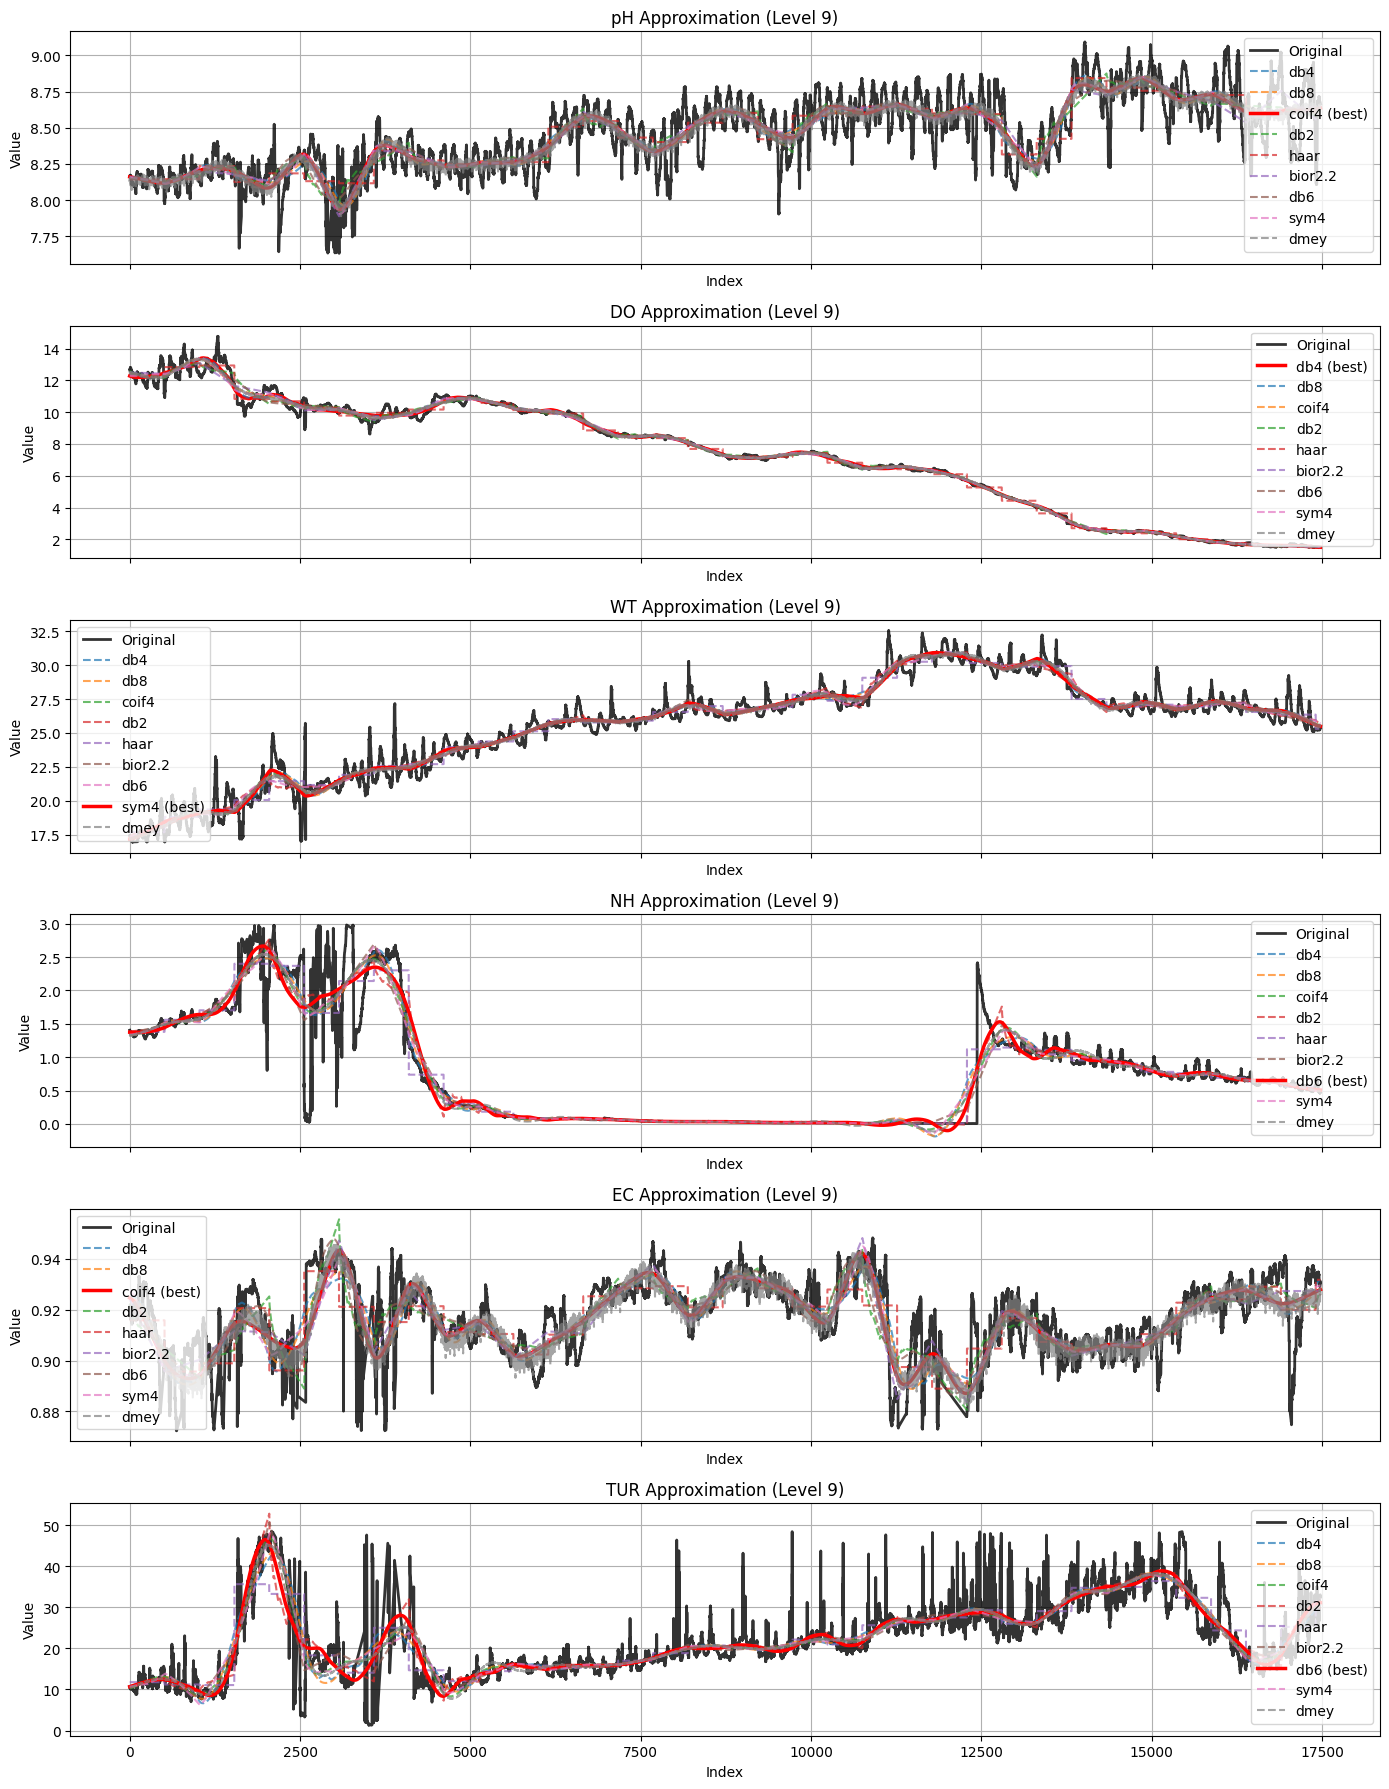

In [27]:
import os
import numpy as np
import pandas as pd
import pywt
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

class ApproxTrend:
    def __init__(self):
        self.wavelet_families = {
            'smooth': ['db4', 'db8', 'coif4'],
            'oscillatory': ['db2', 'haar', 'bior2.2'],
            'irregular': ['db6', 'sym4', 'dmey']
        }

    # ---------------- Multilevel MRA ----------------
    @staticmethod
    def multilevel_1d_mra(data, wavelet='db6', levels=3, mode='symmetric', transform='swt'):
        return pywt.mra(data, wavelet=wavelet, level=levels, mode=mode, transform=transform)

    def get_approximation(self, signal, wavelet='db6', levels=5, transform='dwt', mode='symmetric'):
        """Get the approximation component from MRA"""
        mra_components = self.multilevel_1d_mra(signal, wavelet=wavelet, levels=levels, mode=mode, transform=transform)
        approx = mra_components[0]
        if len(approx) != len(signal):
            approx = np.interp(np.arange(len(signal)), np.arange(len(approx)), approx)
        return approx

    # ---------------- Metrics ----------------
    @staticmethod
    def compute_metrics(original, approx):
        mse = np.mean((original - approx)**2)
        snr_db = 10 * np.log10(np.var(original)/mse) if mse > 0 else float('inf')
        correlation = np.corrcoef(original, approx)[0, 1]
        edges_orig = np.abs(np.diff(original))
        edges_approx = np.abs(np.diff(approx))
        edge_corr = np.corrcoef(edges_orig, edges_approx)[0, 1] if len(edges_orig) > 1 else 1.0
        residual = original - approx
        noise_reduction = np.var(np.diff(original))/np.var(residual) if np.var(residual) > 0 else float('inf')
        peaks_orig, _ = find_peaks(original)
        peak_pres = np.corrcoef(original[peaks_orig], approx[peaks_orig])[0, 1] if len(peaks_orig) > 0 else 1.0
        fft_orig, fft_approx = np.abs(np.fft.fft(original)), np.abs(np.fft.fft(approx))
        spectral_sim = np.corrcoef(fft_orig, fft_approx)[0, 1]
        return {
            'mse': mse,
            'snr_db': snr_db,
            'correlation': correlation,
            'edge_preservation': edge_corr,
            'noise_reduction': noise_reduction,
            'peak_preservation': peak_pres,
            'spectral_similarity': spectral_sim
        }

    # ---------------- Compare wavelets ----------------
    def compare_wavelets(self, signal, levels=5, transform='dwt', mode='symmetric'):
        results = {}
        for family, wavelets in self.wavelet_families.items():
            for wavelet in wavelets:
                approx = self.get_approximation(signal, wavelet=wavelet, levels=levels, transform=transform, mode=mode)
                metrics = self.compute_metrics(signal, approx)
                results[wavelet] = metrics
        return results

    # ---------------- Approximate trends for DataFrame ----------------
    def approximate_trends_dataframe(self, df, levels=5, transform='dwt', mode='symmetric'):
        df_approx = df.copy()
        metrics_stats = {}
        for column in df.select_dtypes(include=[np.number]).columns:
            print(f"Comparing wavelets for {column}...")
            wavelet_results = self.compare_wavelets(df[column].values, levels=levels, transform=transform, mode=mode)
            # Pick best wavelet by SNR
            best_wavelet = max(wavelet_results, key=lambda w: wavelet_results[w]['snr_db'])
            best_approx = self.get_approximation(df[column].values, wavelet=best_wavelet,
                                                 levels=levels, transform=transform, mode=mode)
            df_approx[column] = best_approx
            metrics_stats[column] = wavelet_results
        return df_approx, metrics_stats

    # ---------------- Plot comparisons and save ----------------
    def plot_comparisons(self, df, results, levels=5, transform='dwt', mode='symmetric', save=True):
        numeric_columns = df.select_dtypes(include=[np.number]).columns
        n_cols = len(numeric_columns)
        fig, axes = plt.subplots(n_cols, 1, figsize=(14, 3*n_cols), sharex=True)
        if n_cols == 1:
            axes = [axes]

        for idx, column in enumerate(numeric_columns):
            signal = df[column].values
            ax = axes[idx]
            ax.plot(signal, label='Original', alpha=0.8, linewidth=2, color='black')

            wavelet_results = results[column]
            best_wavelet = max(wavelet_results, key=lambda w: wavelet_results[w]['snr_db'])

            for wavelet in wavelet_results:
                approx = self.get_approximation(signal, wavelet=wavelet, levels=levels, transform=transform, mode=mode)
                if wavelet == best_wavelet:
                    ax.plot(approx, label=f'{wavelet} (best)', linestyle='-', linewidth=2.5, color='red')
                else:
                    ax.plot(approx, label=wavelet, linestyle='--', alpha=0.7)

            ax.set_title(f'{column} Approximation (Level {levels})')
            ax.set_xlabel('Index')
            ax.set_ylabel('Value')
            ax.legend()
            ax.grid(True)

            # Save figure
            if save:
                os.makedirs('./output', exist_ok=True)
                filename = f'./output/{column}_wavelet_comparison.png'
                plt.savefig(filename, dpi=300, bbox_inches='tight')
                print(f'[Saved] {filename}')

        plt.tight_layout()
        plt.show()
        plt.close()

# ---------------- Main ----------------
if __name__ == "__main__":

    preprocessor = WaterQualityPreprocessor()
    # Load dataset
    df = preprocessor.load_and_clean_data("./data/water_quality_data.csv")
    df = df.copy()
    # For performance, limit to last 5000 samples
    #df = df[-5000:]
    # Run preprocessing pipeline
    processed_df = preprocessor.preprocess(df)

    approx_trend = ApproxTrend()
    df_approx, results = approx_trend.approximate_trends_dataframe(processed_df,levels=9, transform='dwt', mode='symmetric')

    # Print benchmark
    print("\n" + "="*80)
    print("COMPREHENSIVE BENCHMARK SUMMARY (Real Data)")
    print("="*80)
    for param, wavelet_results in results.items():
        print(f"\nParameter: {param}")
        for wavelet, metrics in wavelet_results.items():
            print(f"{wavelet:8} | "
                  f"SNR: {metrics['snr_db']:6.2f} dB | "
                  f"Corr: {metrics['correlation']:5.3f} | "
                  f"Edge: {metrics['edge_preservation']:5.3f} | "
                  f"MSE: {metrics['mse']:.6f} | "
                  f"NoiseRed: {metrics['noise_reduction']:.3f} | "
                  f"PeakPres: {metrics['peak_preservation']:.3f} | "
                  f"SpectralSim: {metrics['spectral_similarity']:.3f}")

    # Plot comparisons with best wavelet highlighted and save
    approx_trend.plot_comparisons(df, results, levels=9, transform='dwt', mode='symmetric')

    # Save approximated DataFrame (best wavelet only)
    df_approx.to_csv('./data/water_quality_approx.csv', index=False)

### 4.10.2 Advanced Visualization Components

In [31]:
def create_advanced_dashboard_components():
    """Create advanced visualization components"""
    
    def create_gauge_chart(value, parameter, threshold_ranges):
        """Create gauge chart for parameter monitoring"""
        fig = go.Figure(go.Indicator(
            mode="gauge+number+delta",
            value=value,
            domain={'x': [0, 1], 'y': [0, 1]},
            title={'text': parameter},
            delta={'reference': threshold_ranges['target']},
            gauge={
                'axis': {'range': [None, threshold_ranges['max']]},
                'bar': {'color': "darkblue"},
                'steps': [
                    {'range': [threshold_ranges['min'], threshold_ranges['target']], 'color': "lightgray"},
                    {'range': [threshold_ranges['target'], threshold_ranges['max']], 'color': "gray"}
                ],
                'threshold': {
                    'line': {'color': "red", 'width': 4},
                    'thickness': 0.75,
                    'value': threshold_ranges['alert']
                }
            }
        ))
        
        return fig
    
    def create_3d_parameter_space(df):
        """Create 3D visualization of parameter relationships"""
        fig = go.Figure(data=go.Scatter3d(
            x=df['pH'],
            y=df['DO'],
            z=df['EC'],
            mode='markers',
            marker=dict(
                size=5,
                color=df['WT'],  # Color by temperature
                colorscale='Viridis',
                showscale=True,
                colorbar=dict(title="Temperature (°C)")
            ),
            text=df.index.strftime('%Y-%m-%d %H:%M'),
            hovertemplate='<b>Time:</b> %{text}<br>' +
                         '<b>pH:</b> %{x:.2f}<br>' +
                         '<b>DO:</b> %{y:.2f} mg/L<br>' +
                         '<b>EC:</b> %{z:.0f} μS/cm<br>' +
                         '<b>Temp:</b> %{marker.color:.1f}°C<extra></extra>'
        ))
        
        fig.update_layout(
            title='3D Parameter Space Visualization',
            scene=dict(
                xaxis_title='pH',
                yaxis_title='Dissolved Oxygen (mg/L)',
                zaxis_title='Electrical Conductivity (μS/cm)'
            )
        )
        
        return fig
    
    def create_spectral_analysis_plot(df, parameter):
        """Create spectral analysis plot"""
        from scipy import signal
        
        # Compute power spectral density
        frequencies, psd = signal.welch(
            df[parameter].values,
            fs=1/60,  # 1 sample per minute
            nperseg=256
        )
        
        fig = go.Figure()
        
        fig.add_trace(go.Scatter(
            x=frequencies,
            y=10 * np.log10(psd),
            mode='lines',
            name=f'{parameter} PSD'
        ))
        
        fig.update_layout(
            title=f'Power Spectral Density - {parameter}',
            xaxis_title='Frequency (Hz)',
            yaxis_title='Power/Frequency (dB/Hz)',
            xaxis_type='log'
        )
        
        return fig
    
    return {
        'gauge_chart': create_gauge_chart,
        '3d_plot': create_3d_parameter_space,
        'spectral_plot': create_spectral_analysis_plot
    }

In [ ]:
# Example usage of the dashboard components

import pandas as pd
import numpy as np
import plotly.graph_objects as go

# Import the dashboard components
# from dashboard_componentsr_module import create_advanced_dashboard_components 
# Load the water quality dataset
df_raw = pd.read_csv("./data/water_quality_data.csv", parse_dates=["timestamp"])
df_raw = df_raw.set_index("timestamp").resample("1min").mean().interpolate()

# Initialize dashboard components
components = create_advanced_dashboard_components()

# -------------------------------
# 1. Test Gauge Chart
# -------------------------------
# Example thresholds
thresholds = {
    'min': 6.5,
    'target': 7.0,
    'max': 8.5,
    'alert': 8.0
}

# Pick latest value for pH
latest_ph = df_raw['pH'].iloc[-1]
gauge_fig = components['gauge_chart'](latest_ph, "pH", thresholds)
gauge_fig.show()

# -------------------------------
# 2. Test 3D Parameter Space
# -------------------------------
space_fig = components['3d_plot'](df_raw)
space_fig.show()

# -------------------------------
# 3. Test Spectral Analysis Plot
# -------------------------------
spectral_fig = components['spectral_plot'](df_raw, 'DO')
spectral_fig.show()
